# A dated plan on real history: \$10,000, \$500 a month, two windfalls, then withdrawals, in a momentum portfolio of the S&P 500 (`momentum_12m`) against the index fund

A plan is more than a starting amount. Money goes in on dates, some of it in lumps, and from some date money comes out. This notebook runs one such plan on 33 years of real S&P 500 history, with the library's `plan` and `plan_montecarlo` operations: \$10,000 invested on 2 January 1990, a monthly contribution indexed to inflation (CPI), two extraordinary investments (\$25,000 in March 1999 and \$15,000 in March 2009), and withdrawals of \$3,000 a month from January 2018. It compares two things. The first is two ways of contributing (a **static** schedule of a flat \$500 a month, and a **phased** schedule that saves more in the middle years). The second, which matters less, is the account the money is held in (TFSA, RRSP, taxable). Everything is measured against one baseline: buying and holding the S&P 500 index fund with the same dollars on the same days.

The screen is the portfolio rule that picks the stocks. It is set by the single variable `STRAT` in the first code cell, which is `momentum_12m` here: the ten S&P 500 stocks with the best price return over the previous twelve months, renewed once a year. Changing that one line (to `"dogs"`, for example) re-runs the whole notebook and every sentence below follows the new result; only this title and the licence line are fixed text. The value screens of the library cannot run on this data (Appendix A says why), and momentum is not a better portfolio than the index on it: the notebook says so where it matters.

**LOCAL USE ONLY.** The data is for local use only. The panel is an unlicensed, mixed-source dataset (CRSP-derived for 1968-2006, then Yahoo, Tiingo and Quandl WIKI prices) that you download yourself with `make data-panel` into the git-ignored folder `screenlab/data/panel/`. It is not part of this repository and is not redistributed; do not commit or share the files, or outputs that embed them.

**The baseline rule: every schedule is invested twice, once in the screen and once in the index fund, on the same dates and for the same dollars, in the same account and taxed the same way.** The index fund (the S&P 500 total return, dividends included, less a 0.05% yearly fund fee) is therefore the baseline of each schedule, and it is named in every chart legend and table as "Index fund", followed by the schedule. The numbers describe one historical path under the 2025 Canadian tax tables, with US CPI and the US 10-year yield standing in for Canadian series (Section 7); they are not a forecast. Not tax advice. Nothing is written to disk and nothing leaves your machine. The notebook takes about two minutes to run once the panel is cached (the first call adds a minute while the market snapshots are built).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import altair as alt
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.plan import CashFlow, Phase
from screenlab.realdata import sp500_panel
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.montecarlo import plan_mc
from screenlab.research import plan_charts as pch      # interactive Altair / Vega-Lite charts, with tooltips
from screenlab.research import tax_plots as tp

if not sp500_panel.available():
    raise RuntimeError("The S&P 500 panel is not on this machine: run `make data-panel` once (local use only), then run this notebook again.")

# ---- the choices of the case study -------------------------------------------------------------------------------------------
STRAT = "momentum_12m"                    # THE SCREEN: the one variable to change (try "dogs"); names and sentences below follow from it
SCREEN = pch.screen_label(STRAT)          # its short name in the legs ("Momentum")
SCHEDS = ("static", "phased")             # the two contribution schedules
LEG = pch.leg_names(SCREEN)               # the four legs, named once: (schedule, "screen" | "index") -> "Momentum, static contributions", ...
ACCOUNTS = ["tfsa", "rrsp", "taxable"]
NAME = tp.ACCOUNT_NAME                    # tfsa -> TFSA, rrsp -> RRSP, taxable -> Taxable
ACCT = {"tfsa": "TFSA", "rrsp": "RRSP", "taxable": "taxable account"}      # the account as it reads in a sentence
START, END = "1990-01-01", "2022-12-30"
FIRST = "1990-01-02"
GOAL = 1_500_000                          # nominal dollars, after tax
N_PATHS = 500
WINDFALLS = [CashFlow("1999-03-01", 25_000, "windfall 1999"), CashFlow("2009-03-01", 15_000, "windfall 2009")]
PHASES = (Phase(0, 10, 500, "early years"), Phase(10, 13, 3_000, "peak saving"), Phase(13, 20, 1_000, "later years"))
SCREEN_TEXT = {"momentum_12m": "the ten S&P 500 stocks with the best price return over the previous twelve months",
               "momentum_6m": "the ten S&P 500 stocks with the best price return over the previous six months",
               "dogs": "the ten S&P 500 stocks with the highest trailing dividend yields",
               "stable_high_yield": "the ten highest yielding S&P 500 stocks that have kept their dividend",
               "stable_dividend": "the ten S&P 500 stocks with the steadiest dividends"}

def show(chart):                          # interactive in JupyterLab / VS Code, the same chart as a picture elsewhere
    pch.show(chart)

def panels(charts, title, shared=False, columns=None):     # charts side by side under one figure title
    return pch.compose(charts, title, columns=columns, shared_legend=shared)

def say(text):                            # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                               # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"\\${v:,.0f}"

def sd(v):                                # signed dollars
    return ("+" if v >= 0 else "-") + f"\\${abs(v):,.0f}"

def fmoney(v):                            # dollars for a table cell (no escape: the table is HTML)
    return "-" if v != v else ("-" if v < 0 else "") + f"${abs(v):,.0f}"

def pc(v):                                # a fraction as a percent
    return f"{100 * v:.2f}%"

def pts(v):                               # a fraction as points a year
    return f"{100 * v:.2f}"

def spts(v):                              # signed points a year
    return f"{100 * v:+.2f}"

def mult(a, b):                           # a as a multiple of b
    return f"{a / b:.1f}"

def yrs(v):                               # years to the goal, "never" when it was not reached
    return "never" if v != v else f"{v:.1f}"

def ahead(v, yes="ahead of", no="behind"):    # the word for the sign of a difference (screen minus index fund)
    return yes if v >= 0 else no

def join_and(items):                      # "a, b and c"
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]

def ordn(n):                              # 43 -> 43rd
    n = int(round(n))
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"

def sched_name(s):                        # "static contributions"
    return pch.sched_label(s)

# ---- the runs, once ----------------------------------------------------------------------------------------------------------
lab = Lab.real_sp500(start=START, end=END)          # the point-in-time panel; the cached load takes a few seconds

def tax_config(account, other_income=90_000, rrsp_rate=0.30):
    # other_income: what you earn from work each year; it sets the bracket the portfolio's income is stacked on
    return TaxConfig(model=CanadianTax("AB", other_income=other_income), macro=lab.macro, account=account,
                     rrsp_withdrawal_rate=rrsp_rate)

PLAN = dict(end=END, initial=10_000, periodic=500, frequency="monthly", growth="cpi", extra=WINDFALLS, withdrawals=3_000,
            withdraw_from="2018-01-01", goal=GOAL, rebalance_months=12)
SCHEDULE = {"static": {}, "phased": dict(periodic=0, phases=PHASES, phase_growth="indexed")}      # phase amounts in 1990 dollars, indexed to CPI
plans = {(s, a): lab.plan(STRAT, FIRST, tax=tax_config(a), **{**PLAN, **SCHEDULE[s]}) for s in SCHEDS for a in ACCOUNTS}     # six straight calculations
hold = lab.plan(STRAT, FIRST, tax=tax_config("tfsa"), cash_timing="hold", **PLAN)         # static schedule, contributions wait in cash until the next rebalance
mcs = {s: plan_mc.plan_montecarlo(lab, plans[s, "tfsa"].spec, n_paths=N_PATHS, seed=1, result=plans[s, "tfsa"]) for s in SCHEDS}      # the straight runs are not repeated
replays = {(s, a): plan_mc.plan_montecarlo(lab, plans[s, a].spec, n_paths=2, generator="history", result=plans[s, a]) for s in SCHEDS for a in ACCOUNTS}   # the recorded months in their own order

def m(s, a, row, col):                    # one metric of one run: schedule, account, row strategy | index | difference
    return plans[s, a].metrics.loc[row, col]

R = {s: plans[s, "tfsa"] for s in SCHEDS}           # the primary comparisons are in the TFSA
BANDS = pch.phase_bands(R["phased"])
S = {k: v.series for k, v in plans.items()}

def flows_of(r):
    f = r.flows[r.flows["applied"]].copy()
    f["executed"] = pd.to_datetime(f["executed"])
    return f
FLW = {s: flows_of(R[s]) for s in SCHEDS}
GROSS = {s: float(FLW[s].loc[FLW[s]["amount"] > 0, "amount"].sum()) for s in SCHEDS}          # dollars put in, before the withdrawals
OUT = {s: float(-FLW[s].loc[FLW[s]["amount"] < 0, "amount"].sum()) for s in SCHEDS}
NET = {s: GROSS[s] - OUT[s] for s in SCHEDS}
N_PER = {s: int((FLW[s]["kind"] == "periodic").sum()) for s in SCHEDS}
PER = {s: FLW[s].loc[FLW[s]["kind"] == "periodic", "amount"] for s in SCHEDS}
assert all(abs(NET[s] - m(s, "tfsa", "strategy", "Contributed")) < 1e-6 for s in SCHEDS) and abs(OUT["static"] - OUT["phased"]) < 1e-6
assert all(abs(m(s, a, "strategy", "Contributed") - NET[s]) < 1e-6 and abs(m(s, a, "index", "Contributed") - NET[s]) < 1e-6 for s in SCHEDS for a in ACCOUNTS)

def first_date(series, level):            # first day the series is at or above `level`
    hit = series[series >= level]
    return hit.index[0] if len(hit) else None
WHO = {"screen": "strategy", "index": "index"}
reached = {(s, a, k): first_date(S[s, a][f"{WHO[k]}_after_tax"], GOAL) for s in SCHEDS for a in ACCOUNTS for k in WHO}
REPLAY = {(s, a, k): float(replays[s, a].terminal[f"{WHO[k]}_after_tax"].iloc[0]) for s in SCHEDS for a in ACCOUNTS for k in WHO}
assert all(abs(REPLAY[s, a, k] - m(s, a, WHO[k], "FinalAfterTax")) <= 1e-6 * m(s, a, WHO[k], "FinalAfterTax") for s in SCHEDS for a in ACCOUNTS for k in WHO)
HIST_PCT = {s: float((mcs[s].terminal["strategy_after_tax"] < REPLAY[s, "tfsa", "screen"]).mean()) for s in SCHEDS}
FINAL = {(s, a, k): m(s, a, WHO[k], "FinalAfterTax") for s in SCHEDS for a in ACCOUNTS for k in WHO}
DF = {(s, a): m(s, a, "difference", "FinalAfterTax") for s in SCHEDS for a in ACCOUNTS}        # screen minus index fund, final after tax
DX = {(s, a): m(s, a, "difference", "XIRRAfterTaxReal") for s in SCHEDS for a in ACCOUNTS}     # ... and in XIRR after tax and inflation

# ---- the Summary: every number is read from the runs above ---------------------------------------------------------------------
st, ph = "static", "phased"
n_lead = sum(DF[s, "tfsa"] >= 0 for s in SCHEDS)
if n_lead == 0:
    verdict = (f"On this history {SCREEN} did not beat the index fund under either schedule. It is in the case study because it is the standard "
               f"definition of momentum, not because it did well (Appendix A compares the screens)")
elif n_lead == 2:
    verdict = f"On this history {SCREEN} beat the index fund under both schedules (Appendix A shows how much such a result depends on the screen and on the rebalance timing)"
else:
    verdict = f"On this history {SCREEN} beat the index fund under one schedule and not the other, so the result depends on when the money arrived"
cols = [(s, k) for s in SCHEDS for k in ("screen", "index")]
sumtab = ["| | " + " | ".join(LEG[c] for c in cols) + " |", "|---|" + "---:|" * len(cols)]
for lab_, f in [
    ("Net money in", lambda s, k: usd(NET[s])),
    ("Final wealth after tax", lambda s, k: usd(FINAL[s, "tfsa", k])),
    ("XIRR after tax and inflation", lambda s, k: pc(m(s, "tfsa", WHO[k], "XIRRAfterTaxReal"))),
    (f"Years to the {usd(GOAL)} goal", lambda s, k: yrs(m(s, "tfsa", WHO[k], "YearsToGoal"))),
    ("Versus the index fund, same schedule: final wealth", lambda s, k: sd(DF[s, "tfsa"]) if k == "screen" else "baseline"),
    ("Versus the index fund, same schedule: XIRR points a year", lambda s, k: spts(DX[s, "tfsa"]) if k == "screen" else "baseline")]:
    sumtab.append(f"| {lab_} | " + " | ".join(f(s, k) for s, k in cols) + " |")
SUMTAB = "\n".join(sumtab)
more_net = NET[ph] - NET[st]
sched_fx = {k: (FINAL[ph, "tfsa", k] - FINAL[st, "tfsa", k], m(ph, "tfsa", WHO[k], "XIRRAfterTaxReal") - m(st, "tfsa", WHO[k], "XIRRAfterTaxReal")) for k in WHO}
best = {c: max(ACCOUNTS, key=lambda a: FINAL[c[0], a, c[1]]) for c in cols}
worst = {c: min(ACCOUNTS, key=lambda a: FINAL[c[0], a, c[1]]) for c in cols}
acct_txt = "; ".join(f"{LEG[c]} {usd(FINAL[c[0], best[c], c[1]])} in the {ACCT[best[c]]} and {usd(FINAL[c[0], worst[c], c[1]])} in the {ACCT[worst[c]]}" for c in cols)
mt = mcs
say(f'''
## Summary

**What was done.** From January 1990 to December 2022 the case study put {usd(GROSS[st])} (static: {usd(PLAN["initial"])} at the start, {N_PER[st]} monthly contributions indexed to CPI from {usd(PER[st].iloc[0])} to {usd(PER[st].iloc[-1])}, two windfalls) or {usd(GROSS[ph])} (phased: the same start and windfalls, {N_PER[ph]} contributions rising from {usd(PER[ph].iloc[0])} to a peak of {usd(PER[ph].max())} and back down) into {SCREEN.lower()} ({STRAT}: {SCREEN_TEXT.get(STRAT, "the screen's stocks")}, renewed every year) and, on the same days for the same dollars, into the S&P 500 index fund, and took {usd(OUT[st])} back out from January 2018. The table is the TFSA, where there is no tax on gains and withholding is the only tax.

{SUMTAB}

**The primary finding: the screen against the index fund, and one schedule against the other.** Under static contributions {SCREEN} finished {usd(abs(DF[st, "tfsa"]))} {ahead(DF[st, "tfsa"])} the index fund ({usd(FINAL[st, "tfsa", "screen"])} against {usd(FINAL[st, "tfsa", "index"])}), with a money-weighted return after tax and inflation of {pc(m(st, "tfsa", "strategy", "XIRRAfterTaxReal"))} against {pc(m(st, "tfsa", "index", "XIRRAfterTaxReal"))}, {pts(abs(DX[st, "tfsa"]))} points {ahead(DX[st, "tfsa"], "above", "below")}. Under phased contributions it finished {usd(abs(DF[ph, "tfsa"]))} {ahead(DF[ph, "tfsa"])} the index fund ({pc(m(ph, "tfsa", "strategy", "XIRRAfterTaxReal"))} against {pc(m(ph, "tfsa", "index", "XIRRAfterTaxReal"))}, {pts(abs(DX[ph, "tfsa"]))} points {ahead(DX[ph, "tfsa"], "above", "below")}). {verdict}. The schedules differ by the money they use: the phased schedule puts in {usd(abs(more_net))} {ahead(more_net, "more", "less")} net money, and finishes {usd(abs(sched_fx["screen"][0]))} {ahead(sched_fx["screen"][0], "higher", "lower")} in {SCREEN.lower()} and {usd(abs(sched_fx["index"][0]))} {ahead(sched_fx["index"][0], "higher", "lower")} in the index fund, while the XIRR after tax and inflation moves {spts(sched_fx["screen"][1])} points for {SCREEN.lower()} and {spts(sched_fx["index"][1])} points for the index fund.

**The secondary finding: the account, and the risk.** The same four legs end best in one account and worst in another, after tax: {acct_txt}. In the TFSA the only tax is the 15% US withholding on dividends; the RRSP is shown after a flat 30% withdrawal tax with no refund counted on the way in; the taxable account pays tax on dividends and realized gains every year. On risk, {SCREEN.lower()} had a beta of {m(st, "tfsa", "strategy", "Beta"):.2f}, an alpha of {pc(m(st, "tfsa", "strategy", "Alpha"))} a year, a Sharpe ratio of {m(st, "tfsa", "strategy", "Sharpe"):.2f} against {m(st, "tfsa", "index", "Sharpe"):.2f} and a worst fall of {pc(-m(st, "tfsa", "strategy", "MaxDD"))} against {pc(-m(st, "tfsa", "index", "MaxDD"))}; on {N_PATHS} resampled orders of the same months in the TFSA it finished ahead of the index fund after tax on {pc(mt[st].p_beat_index)} of paths under static and {pc(mt[ph].p_beat_index)} under phased contributions, and ended below the {usd(GOAL)} goal on {pc(mt[st].p_shortfall)} and {pc(mt[ph].p_shortfall)} of paths (the index fund: {pc(mt[st].p_shortfall_index)} and {pc(mt[ph].p_shortfall_index)}).
''')


## Summary

**What was done.** From January 1990 to December 2022 the case study put \$295,904 (static: \$10,000 at the start, 336 monthly contributions indexed to CPI from \$500 to \$953, two windfalls) or \$396,892 (phased: the same start and windfalls, 240 contributions rising from \$500 to a peak of \$4,170 and back down) into momentum (momentum_12m: the ten S&P 500 stocks with the best price return over the previous twelve months, renewed every year) and, on the same days for the same dollars, into the S&P 500 index fund, and took \$180,000 back out from January 2018. The table is the TFSA, where there is no tax on gains and withholding is the only tax.

| | Momentum, static contributions | Index fund, static contributions | Momentum, phased contributions | Index fund, phased contributions |
|---|---:|---:|---:|---:|
| Net money in | \$115,904 | \$115,904 | \$216,892 | \$216,892 |
| Final wealth after tax | \$1,393,105 | \$1,558,015 | \$1,676,580 | \$2,158,435 |
| XIRR after tax and inflation | 5.83% | 6.27% | 4.80% | 5.84% |
| Years to the \$1,500,000 goal | 31.8 | 30.7 | 31.5 | 27.8 |
| Versus the index fund, same schedule: final wealth | -\$164,910 | baseline | -\$481,855 | baseline |
| Versus the index fund, same schedule: XIRR points a year | -0.44 | baseline | -1.04 | baseline |

**The primary finding: the screen against the index fund, and one schedule against the other.** Under static contributions Momentum finished \$164,910 behind the index fund (\$1,393,105 against \$1,558,015), with a money-weighted return after tax and inflation of 5.83% against 6.27%, 0.44 points below. Under phased contributions it finished \$481,855 behind the index fund (4.80% against 5.84%, 1.04 points below). On this history Momentum did not beat the index fund under either schedule. It is in the case study because it is the standard definition of momentum, not because it did well (Appendix A compares the screens). The schedules differ by the money they use: the phased schedule puts in \$100,988 more net money, and finishes \$283,475 higher in momentum and \$600,420 higher in the index fund, while the XIRR after tax and inflation moves -1.03 points for momentum and -0.43 points for the index fund.

**The secondary finding: the account, and the risk.** The same four legs end best in one account and worst in another, after tax: Momentum, static contributions \$1,393,105 in the TFSA and \$997,418 in the RRSP; Index fund, static contributions \$1,558,015 in the TFSA and \$1,172,391 in the RRSP; Momentum, phased contributions \$1,676,580 in the TFSA and \$1,201,633 in the RRSP; Index fund, phased contributions \$2,158,435 in the TFSA and \$1,621,186 in the RRSP. In the TFSA the only tax is the 15% US withholding on dividends; the RRSP is shown after a flat 30% withdrawal tax with no refund counted on the way in; the taxable account pays tax on dividends and realized gains every year. On risk, momentum had a beta of 1.17, an alpha of 0.58% a year, a Sharpe ratio of 0.30 against 0.41 and a worst fall of 85.38% against 55.28%; on 500 resampled orders of the same months in the TFSA it finished ahead of the index fund after tax on 50.20% of paths under static and 49.60% under phased contributions, and ended below the \$1,500,000 goal on 45.20% and 35.00% of paths (the index fund: 42.00% and 24.20%).


In [2]:
# How to read this notebook: the comparison map. Names come from the variables above.
DESC = SCREEN_TEXT.get(STRAT, "the stocks the screen picks")
say(f'''
## How to read this notebook

Two contribution schedules, two instruments, one baseline rule. Every schedule is invested twice, once in the screen and once in the index fund, on the same dates and for the same dollars, so each row of the table is a fair fight and the index fund in a row is the baseline for that row.

| | **{SCREEN}** (the screen: {DESC}, renewed yearly) | **Index fund** (the baseline: the S&P 500 total return, bought and held, 0.05% fee) |
|---|---|---|
| **Static contributions** (a flat {usd(PLAN["periodic"])} a month, indexed to CPI) | {LEG["static", "screen"]}: the screen fed the static schedule | {LEG["static", "index"]}: the baseline of the static schedule |
| **Phased contributions** (years 0 to 10 {usd(PHASES[0].amount)}, 10 to 13 {usd(PHASES[1].amount)}, 13 to 20 {usd(PHASES[2].amount)} a month, indexed) | {LEG["phased", "screen"]}: the screen fed the phased schedule | {LEG["phased", "index"]}: the baseline of the phased schedule |

Both schedules start with the same {usd(PLAN["initial"])}, receive the same two windfalls and take out the same {usd(PLAN["withdrawals"])} a month from 2018. The first comparison reads a row across (the screen against its own baseline, Sections 2 and 3). The second reads a column down (static against phased, for the screen and for the index fund separately, Section 3), by the money-weighted return and not by final dollars alone, because the phased schedule puts in more money. The primary comparisons are in the TFSA, which has no tax on gains and so isolates the strategy; the secondary one is the account (TFSA, RRSP at a 30% withdrawal rate, taxable in Alberta with other income of {usd(90_000)}), the same four legs in each (Section 4). In every chart the colour is the schedule, a solid line is the screen and a dashed lighter line of the same colour is the index fund.
''')


## How to read this notebook

Two contribution schedules, two instruments, one baseline rule. Every schedule is invested twice, once in the screen and once in the index fund, on the same dates and for the same dollars, so each row of the table is a fair fight and the index fund in a row is the baseline for that row.

| | **Momentum** (the screen: the ten S&P 500 stocks with the best price return over the previous twelve months, renewed yearly) | **Index fund** (the baseline: the S&P 500 total return, bought and held, 0.05% fee) |
|---|---|---|
| **Static contributions** (a flat \$500 a month, indexed to CPI) | Momentum, static contributions: the screen fed the static schedule | Index fund, static contributions: the baseline of the static schedule |
| **Phased contributions** (years 0 to 10 \$500, 10 to 13 \$3,000, 13 to 20 \$1,000 a month, indexed) | Momentum, phased contributions: the screen fed the phased schedule | Index fund, phased contributions: the baseline of the phased schedule |

Both schedules start with the same \$10,000, receive the same two windfalls and take out the same \$3,000 a month from 2018. The first comparison reads a row across (the screen against its own baseline, Sections 2 and 3). The second reads a column down (static against phased, for the screen and for the index fund separately, Section 3), by the money-weighted return and not by final dollars alone, because the phased schedule puts in more money. The primary comparisons are in the TFSA, which has no tax on gains and so isolates the strategy; the secondary one is the account (TFSA, RRSP at a 30% withdrawal rate, taxable in Alberta with other income of \$90,000), the same four legs in each (Section 4). In every chart the colour is the schedule, a solid line is the screen and a dashed lighter line of the same colour is the index fund.


## 1. The setup and the flows

The first question is what each schedule does with money, and when. Every later number depends on it, because a return on a dollar that arrived in year 28 means something different from a return on a dollar that arrived in year 1, and a dollar taken out in 2018 is a dollar that stops compounding. This section makes no comparison of returns yet: it fixes the two schedules and the four legs the rest of the notebook compares. Both schedules start with \$10,000 on the first trading day of 1990, receive two dated windfalls (\$25,000 in March 1999 and \$15,000 in March 2009) and take out \$3,000 a month from January 2018. They differ in the monthly contribution. The **static** schedule puts in a flat \$500 a month, indexed to US CPI, and stops on the day the withdrawals start. The **phased** schedule is the owner's base case: \$500 a month in years 0 to 10 (1990 to 1999), \$3,000 in years 10 to 13 (2000 to 2002) and \$1,000 in years 13 to 20 (2003 to 2009), each amount in 1990 dollars and indexed to CPI, and nothing between January 2010 and the start of the withdrawals. It is an illustration of what might be available to invest at each stage of life, not a forecast of anyone's income. A flow dated on a non-trading day executes on the next trading day, and the index fund receives exactly the same dollars on exactly the same days, less its 0.05% yearly fee.

Figure 1 shows, in the top panels, the dollars that went in and out in each calendar year by kind, one panel per schedule, and below them the running total of net money in for the four legs.

**Figure 1.** Top: dollars in and out each year, stacked by kind, for the static schedule (left) and the phased schedule (right, with the contributions stacked by phase). Bottom: the running total of net money in (contributions less withdrawals) for the four legs. **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** Because the index fund is fed the same dollars, each dashed line runs exactly under the solid line of its schedule. **Tooltip:** on a bar, the schedule, year, kind of flow, dollars and number of flows that year; on the running total, the year end, the leg and the net money in so far. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

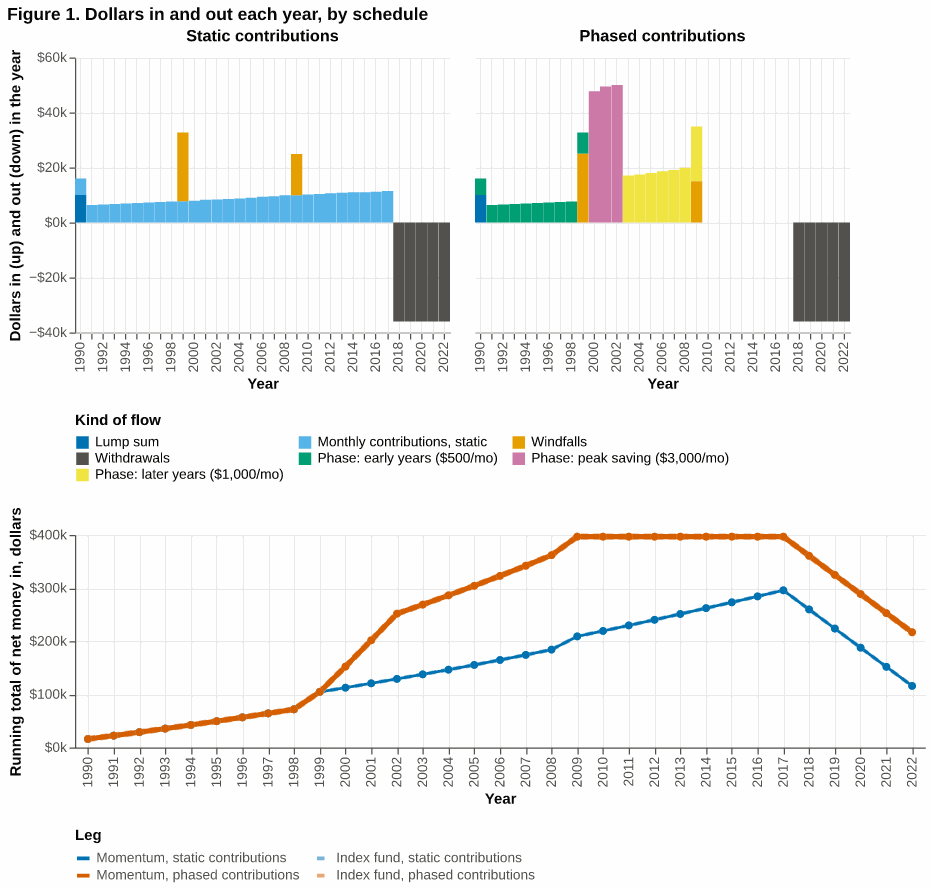

Table 1. The flows of the two schedules, 1990-2022 (the index fund receives the same flows)


In [3]:
show(pch.compare_flows_chart({s: R[s] for s in SCHEDS}, SCREEN, title="Figure 1. Dollars in and out each year, by schedule"))

kinds = {"initial": "Lump sum", "periodic": "Monthly contributions", "extra": "Windfalls", "withdrawal": "Withdrawals"}
tab1 = pd.DataFrame({(sched_name(s).capitalize(), c): (FLW[s].groupby("kind")["amount"].size() if c == "Flows" else FLW[s].groupby("kind")["amount"].sum()).reindex(list(kinds))
                     for s in SCHEDS for c in ("Flows", "Dollars")})
tab1.index = list(kinds.values())
tab1.loc["Net money in (the same for the index fund)"] = [v for s in SCHEDS for v in (len(FLW[s]), FLW[s]["amount"].sum())]
print("Table 1. The flows of the two schedules, 1990-2022 (the index fund receives the same flows)")
tab1.style.format({c: ("{:,.0f}" if c[1] == "Flows" else fmoney) for c in tab1.columns}, na_rep="-")

In [4]:
end_ts = pd.Timestamp(END)
WINDOW = (end_ts - pd.Timestamp(FIRST)).days / 365.25
def age_late(s):
    con = FLW[s][FLW[s]["amount"] > 0]
    avg = float((con["amount"] * (end_ts - con["executed"]).dt.days / 365.25).sum() / con["amount"].sum())
    late = con.loc[con["executed"] >= "2005-01-01", "amount"].sum() / con["amount"].sum()
    return avg, late
AGE, LATE = {s: age_late(s)[0] for s in SCHEDS}, {s: age_late(s)[1] for s in SCHEDS}
WF = WINDFALLS[0].amount + WINDFALLS[1].amount
say(f'''
### What the evidence says

The two schedules use very different amounts of money. The static schedule put in {usd(GROSS["static"])} and took out {usd(OUT["static"])}, for net money in of {usd(NET["static"])}; the phased schedule put in {usd(GROSS["phased"])}, {usd(GROSS["phased"] - GROSS["static"])} ({pc(GROSS["phased"] / GROSS["static"] - 1)}) more, and so had net money in of {usd(NET["phased"])}, {mult(NET["phased"], NET["static"])} times the static schedule's. Both are back-loaded. Weighted by dollars, the average dollar of the static schedule was invested for {AGE["static"]:.1f} years and of the phased schedule for {AGE["phased"]:.1f}, not the {WINDOW:.1f} years the window spans, and {pc(LATE["static"])} and {pc(LATE["phased"])} of the money went in after 2004. The two windfalls ({usd(WF)}, {pc(WF / GROSS["static"])} of the static schedule's money in and {pc(WF / GROSS["phased"])} of the phased schedule's) arrived in March 1999, on the way up to the dot-com peak, and in March 2009, the month of the financial-crisis low. That timing is why a money-weighted return and the return of one dollar left alone for 33 years differ in Section 2, and why the index fund fed the same dollars on the same days is the fair baseline: both legs of a schedule receive them together, so any gap within a schedule belongs to the screen and not to the schedule.
''')
assert max(AGE.values()) < WINDOW - 5 and NET["phased"] > NET["static"]


### What the evidence says

The two schedules use very different amounts of money. The static schedule put in \$295,904 and took out \$180,000, for net money in of \$115,904; the phased schedule put in \$396,892, \$100,988 (34.13%) more, and so had net money in of \$216,892, 1.9 times the static schedule's. Both are back-loaded. Weighted by dollars, the average dollar of the static schedule was invested for 18.4 years and of the phased schedule for 21.1, not the 33.0 years the window spans, and 50.51% and 27.84% of the money went in after 2004. The two windfalls (\$40,000, 13.52% of the static schedule's money in and 10.08% of the phased schedule's) arrived in March 1999, on the way up to the dot-com peak, and in March 2009, the month of the financial-crisis low. That timing is why a money-weighted return and the return of one dollar left alone for 33 years differ in Section 2, and why the index fund fed the same dollars on the same days is the fair baseline: both legs of a schedule receive them together, so any gap within a schedule belongs to the screen and not to the schedule.


## 2. Static contributions: the screen against the index fund

The question for this section is whether the screen did better than the index fund when both were fed the static schedule, a flat \$500 a month indexed to CPI. It makes the first primary comparison of the notebook, one row of the map read across, and it follows from Section 1 by taking the static schedule's two legs and nothing else. It is made in the TFSA, where gains are not taxed and the only tax is the withholding on foreign dividends, so the gap between the legs is the strategy's and not the account's.

The calculation follows each dollar. A contribution on a trading day buys the screen's current ten names in equal weights (paying the library's trading cost, 25 basis points a side), a withdrawal sells pro rata, the yearly rebalance renews the ten names, and the dividends are reinvested. The index fund leg buys the S&P 500 total return less the 0.05% fund fee. Tax is paid from the portfolio, as in every other backtest of the library: at each year's last trading day the year's tax is sold out of the holdings, and the last year's tax and the tax on the gains realized at the end come out on the last day, so the after-tax line is the wealth the investor would actually have held.

"The strategy returned x% a year" means two different things when money moves in and out, and the plan reports both. The **XIRR** (money-weighted return) is the single yearly rate that, applied to every dated flow, makes the contributions grow to the final value and the withdrawals match; it is what the investor's own dollars earned, so it depends on when the money was there to earn it. The **TWR** (time-weighted return) strips the flows out: it is the yearly growth of one dollar left in the strategy for the whole window, the record of the strategy itself, and it is the series the risk measures are computed on. Alpha, beta and Sharpe come from monthly time-weighted returns: beta and alpha are the slope and intercept of the strategy's monthly excess return (over the US 10-year yield, a stand-in) on the index's, alpha annualised, and Sharpe is the mean excess return over its standard deviation, times the square root of 12.

Figure 2 draws the static schedule's two legs on a logarithmic scale, and Table 2 gives the plan's three-row result, the screen, the index fund and the difference, with the money-weighted return counted four ways: before tax, after tax, after inflation (every flow deflated by CPI to 1990 dollars) and after both.

**Figure 2.** TFSA wealth after tax under the static schedule, on a log scale: the screen (solid blue), the index fund that received the same dollars (dashed light blue), the net money put in (dotted) and the \$1.5 million goal (amber). **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** hovering shows the month end, the money put in, both legs (after tax) and the screen minus the index fund. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

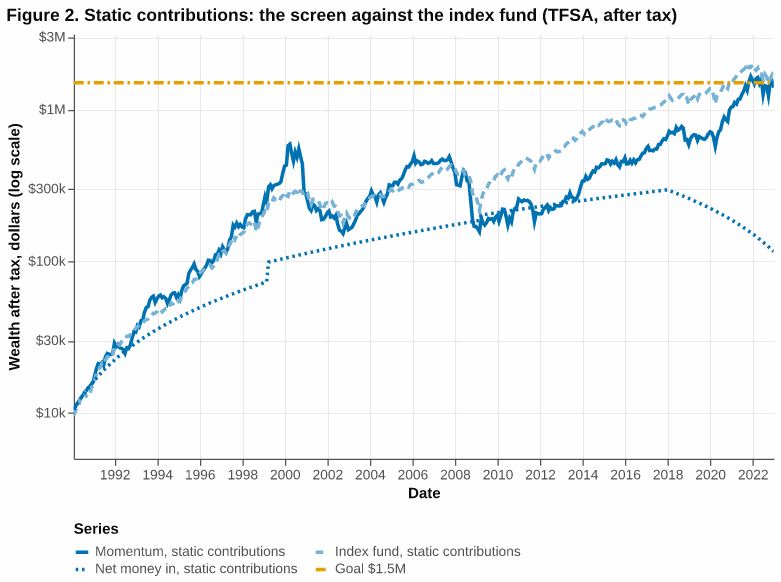

Table 2. Static contributions in the TFSA: the screen, the index fund (the baseline) and the difference


,Contributed,FinalPreTax,FinalAfterTax,FinalAfterTaxReal,XIRR,XIRRAfterTax,XIRRReal,XIRRAfterTaxReal,TWR,Alpha,Beta,Sharpe,Vol,MaxDD,TaxPaid
"Momentum, static contributions","$115,904","$1,424,902","$1,393,105","$597,990",8.52%,8.43%,5.92%,5.83%,8.94%,0.58%,1.17,0.30,25.47%,-85.38%,"$11,706"
"Index fund, static contributions","$115,904","$1,674,844","$1,558,015","$668,777",9.18%,8.89%,6.56%,6.27%,9.54%,0.00%,1.00,0.41,15.00%,-55.28%,"$45,491"
Difference (screen minus index fund),$0,"-$249,942","-$164,910","-$70,787",-0.66%,-0.46%,-0.64%,-0.44%,-0.60%,0.58%,0.17,-0.10,10.48%,-30.10%,"-$33,785"


In [5]:
WEALTH_DOM = (5_000, 1.15 * max(float(S[s, a][f"{w}_after_tax"].max()) for s in SCHEDS for a in ACCOUNTS for w in ("strategy", "index")))
show(pch.compare_chart({"static": R["static"]}, SCREEN, y_domain=WEALTH_DOM, title="Figure 2. Static contributions: the screen against the index fund (TFSA, after tax)"))

cols_t = ["Contributed", "FinalPreTax", "FinalAfterTax", "FinalAfterTaxReal", "XIRR", "XIRRAfterTax", "XIRRReal", "XIRRAfterTaxReal", "TWR", "Alpha", "Beta", "Sharpe", "Vol", "MaxDD", "TaxPaid"]
money_c = ["Contributed", "FinalPreTax", "FinalAfterTax", "FinalAfterTaxReal", "TaxPaid"]
pct_c = ["XIRR", "XIRRAfterTax", "XIRRReal", "XIRRAfterTaxReal", "TWR", "Alpha", "Vol", "MaxDD"]
def metrics_table(s):
    t = R[s].metrics[cols_t].copy()
    t.index = [LEG[s, "screen"], LEG[s, "index"], "Difference (screen minus index fund)"]
    return t.style.format({c: fmoney for c in money_c} | {c: "{:.2%}" for c in pct_c} | {"Beta": "{:.2f}", "Sharpe": "{:.2f}"}, na_rep="-")
print("Table 2. Static contributions in the TFSA: the screen, the index fund (the baseline) and the difference")
metrics_table("static")

In [6]:
def risk_story(s):
    a = lambda c, w: m(s, "tfsa", w, c)
    ret_lead = DX[s, "tfsa"] >= 0
    risk_up = a("Vol", "strategy") > a("Vol", "index") or a("MaxDD", "strategy") < a("MaxDD", "index")
    return ("The lead came with more risk." if ret_lead and risk_up else "The lead came with no extra risk." if ret_lead else
            "It carried more risk and earned less, which is the wrong direction on both counts." if risk_up else "It carried less risk and earned less, the usual trade.")
def story(s):
    a = lambda c, w: m(s, "tfsa", w, c)
    L, I = LEG[s, "screen"], LEG[s, "index"]
    both = (a("XIRR", "difference") >= 0) == (a("TWR", "difference") >= 0)
    return f'''In the TFSA, {L} turned {usd(NET[s])} of net money into {usd(a("FinalPreTax", "strategy"))} before tax ({mult(a("FinalPreTax", "strategy"), NET[s])} times what was put in) and {usd(a("FinalAfterTax", "strategy"))} after tax, against {usd(a("FinalPreTax", "index"))} and {usd(a("FinalAfterTax", "index"))} for {I}. After tax the screen finished {usd(abs(DF[s, "tfsa"]))} {ahead(DF[s, "tfsa"])} the index fund of the same schedule. Its money-weighted return was {pc(a("XIRR", "strategy"))} a year before tax and {pc(a("XIRRAfterTaxReal", "strategy"))} after tax and inflation, against {pc(a("XIRR", "index"))} and {pc(a("XIRRAfterTaxReal", "index"))} for the index fund, a difference of {spts(a("XIRRAfterTaxReal", "difference"))} points after tax and inflation; its time-weighted return was {pc(a("TWR", "strategy"))} against {pc(a("TWR", "index"))} ({spts(a("TWR", "difference"))} points). The two measures {"agree" if both else "disagree"} on the sign, so the timing of the flows {"did not manufacture" if both else "changed the sign of"} the gap. Counted four ways, the screen's XIRR falls from {pc(a("XIRR", "strategy"))} before tax to {pc(a("XIRRAfterTax", "strategy"))} after tax (the 15% US withholding on dividends), to {pc(a("XIRRReal", "strategy"))} after inflation and to {pc(a("XIRRAfterTaxReal", "strategy"))} after both.

On risk, the screen's beta was {a("Beta", "strategy"):.2f} and its alpha {pc(a("Alpha", "strategy"))} a year; its Sharpe ratio was {a("Sharpe", "strategy"):.2f} against {a("Sharpe", "index"):.2f} for the index fund; it was {pc(a("Vol", "strategy"))} volatile against {pc(a("Vol", "index"))}, fell {pc(-a("MaxDD", "strategy"))} at the worst against {pc(-a("MaxDD", "index"))}, and had a tracking error of {pc(a("TrackingError", "strategy"))} and an information ratio of {a("InfoRatio", "strategy"):.2f}. {risk_story(s)} A gap of {pts(abs(a("TWR", "difference")))} points a year with an information ratio of {a("InfoRatio", "strategy"):.2f} is a t-statistic of about {abs(a("InfoRatio", "strategy")) * WINDOW ** 0.5:.1f} over {WINDOW:.0f} years, {"within what one history can produce by luck" if abs(a("InfoRatio", "strategy")) * WINDOW ** 0.5 < 2 else "large for one history, though not a proof"}; Section 6 puts a number on it.'''
say("### What the evidence says\n\n" + story("static"))

### What the evidence says

In the TFSA, Momentum, static contributions turned \$115,904 of net money into \$1,424,902 before tax (12.3 times what was put in) and \$1,393,105 after tax, against \$1,674,844 and \$1,558,015 for Index fund, static contributions. After tax the screen finished \$164,910 behind the index fund of the same schedule. Its money-weighted return was 8.52% a year before tax and 5.83% after tax and inflation, against 9.18% and 6.27% for the index fund, a difference of -0.44 points after tax and inflation; its time-weighted return was 8.94% against 9.54% (-0.60 points). The two measures agree on the sign, so the timing of the flows did not manufacture the gap. Counted four ways, the screen's XIRR falls from 8.52% before tax to 8.43% after tax (the 15% US withholding on dividends), to 5.92% after inflation and to 5.83% after both.

On risk, the screen's beta was 1.17 and its alpha 0.58% a year; its Sharpe ratio was 0.30 against 0.41 for the index fund; it was 25.47% volatile against 15.00%, fell 85.38% at the worst against 55.28%, and had a tracking error of 18.66% and an information ratio of 0.09. It carried more risk and earned less, which is the wrong direction on both counts. A gap of 0.60 points a year with an information ratio of 0.09 is a t-statistic of about 0.5 over 33 years, within what one history can produce by luck; Section 6 puts a number on it.

## 3. Phased contributions: the same comparison, then the schedule effect

The question for this section is what changes when the monthly contribution follows the phases of life instead of staying at \$500. It does two things. First it repeats the Section 2 comparison on the phased schedule, the screen against the index fund that received the same dollars, which is the second row of the map read across. Then it compares the two schedules with each other, instrument by instrument: static against phased momentum, and static against phased index fund, which is the map read down. Final dollars alone would mislead, because the phased schedule puts in much more money, so the comparison uses the money-weighted return as well. The phases are the ones of Section 1, shaded as bands behind the lines of Figure 3.

Figure 3 draws the phased schedule's two legs with the three phases shaded. Figure 4 puts all four legs on one set of axes. Table 3 is the phased schedule's three-row result, and Table 4 gives the four legs side by side and the effect of the schedule on each instrument.

**Figure 3.** TFSA wealth after tax under the phased schedule on a log scale, with the three contribution phases shaded: the screen (solid vermillion), the index fund (dashed lighter vermillion), the net money put in (dotted) and the goal (amber). **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** on a line, the month end, the money put in, both legs after tax and the screen minus the index fund; on a shaded band, the phase, its start and end dates, the plan years, the amount per month in 1990 dollars, the note and the total contributed in the phase. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

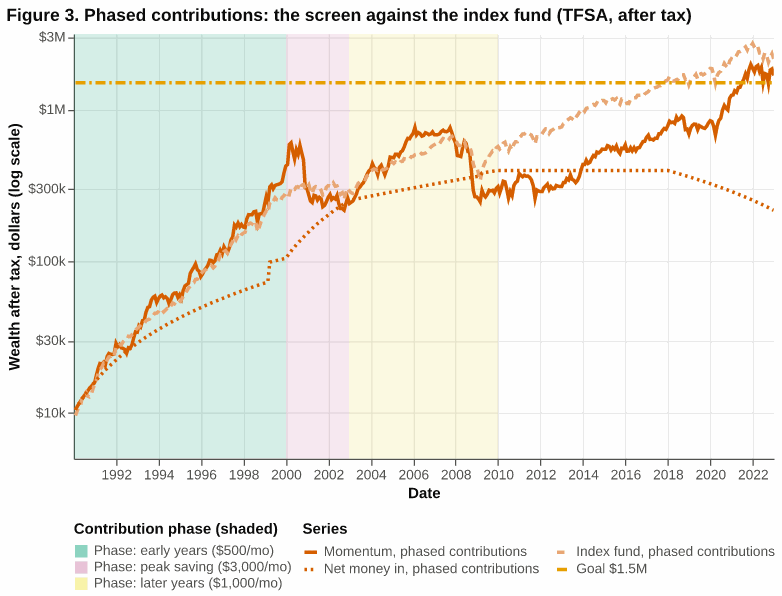

Table 3. Phased contributions in the TFSA: the screen, the index fund (the baseline) and the difference


,Contributed,FinalPreTax,FinalAfterTax,FinalAfterTaxReal,XIRR,XIRRAfterTax,XIRRReal,XIRRAfterTaxReal,TWR,Alpha,Beta,Sharpe,Vol,MaxDD,TaxPaid
"Momentum, phased contributions","$216,892","$1,716,640","$1,676,580","$719,671",7.45%,7.35%,4.90%,4.80%,8.95%,0.58%,1.17,0.30,25.47%,-85.32%,"$14,502"
"Index fund, phased contributions","$216,892","$2,315,980","$2,158,435","$926,507",8.72%,8.42%,6.13%,5.84%,9.54%,0.00%,1.00,0.41,15.00%,-55.28%,"$62,692"
Difference (screen minus index fund),$0,"-$599,340","-$481,855","-$206,836",-1.27%,-1.07%,-1.23%,-1.04%,-0.59%,0.58%,0.17,-0.10,10.48%,-30.04%,"-$48,190"


In [7]:
show(pch.compare_chart({"phased": R["phased"]}, SCREEN, y_domain=WEALTH_DOM, bands=BANDS, title="Figure 3. Phased contributions: the screen against the index fund (TFSA, after tax)"))
print("Table 3. Phased contributions in the TFSA: the screen, the index fund (the baseline) and the difference")
metrics_table("phased")

**Figure 4.** TFSA wealth after tax, all four legs on one log scale: static contributions in blue and phased contributions in vermillion, the screen solid and the index fund dashed and lighter. **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** hovering shows the month end, the money put in under each schedule, the four legs after tax and, for each schedule, the screen minus the index fund. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

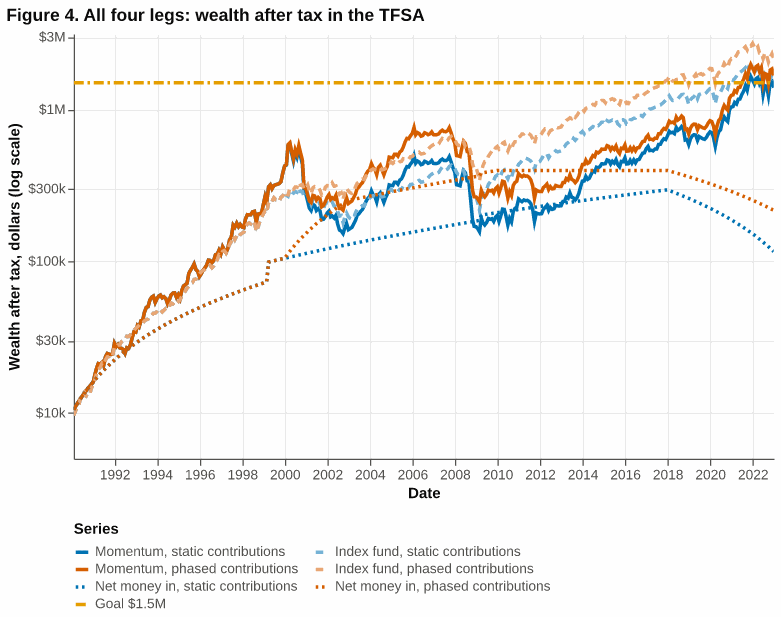

Table 4. The four legs in the TFSA, and the effect of the schedule on each instrument (contributed = lump sum, contributions and windfalls, before withdrawals)


,Contributed,Net money in,"Final, after tax","XIRR, before tax","XIRR, after tax and inflation",Years to the goal
Leg,,,,,,
"Momentum, static contributions","$295,904","$115,904","$1,393,105",8.52%,5.83%,31.8
"Index fund, static contributions","$295,904","$115,904","$1,558,015",9.18%,6.27%,30.7
"Momentum, phased contributions","$396,892","$216,892","$1,676,580",7.45%,4.80%,31.5
"Index fund, phased contributions","$396,892","$216,892","$2,158,435",8.72%,5.84%,27.8
Momentum: phased minus static,"$100,988","$100,988","$283,475",-1.07%,-1.03%,-0.3
Index fund: phased minus static,"$100,988","$100,988","$600,420",-0.46%,-0.43%,-2.9


In [8]:
show(pch.compare_chart(R, SCREEN, y_domain=WEALTH_DOM, title="Figure 4. All four legs: wealth after tax in the TFSA"))

rows = []
for s in SCHEDS:
    for k in ("screen", "index"):
        rows.append({"Leg": LEG[s, k], "Contributed": GROSS[s], "Net money in": NET[s], "Final, after tax": FINAL[s, "tfsa", k],
                     "XIRR, before tax": m(s, "tfsa", WHO[k], "XIRR"), "XIRR, after tax and inflation": m(s, "tfsa", WHO[k], "XIRRAfterTaxReal"),
                     "Years to the goal": m(s, "tfsa", WHO[k], "YearsToGoal")})
for k, nm in (("screen", SCREEN), ("index", "Index fund")):
    a_, b_ = m("phased", "tfsa", WHO[k], "XIRRAfterTaxReal"), m("static", "tfsa", WHO[k], "XIRRAfterTaxReal")
    rows.append({"Leg": f"{nm}: phased minus static", "Contributed": GROSS["phased"] - GROSS["static"], "Net money in": NET["phased"] - NET["static"],
                 "Final, after tax": FINAL["phased", "tfsa", k] - FINAL["static", "tfsa", k],
                 "XIRR, before tax": m("phased", "tfsa", WHO[k], "XIRR") - m("static", "tfsa", WHO[k], "XIRR"), "XIRR, after tax and inflation": a_ - b_,
                 "Years to the goal": m("phased", "tfsa", WHO[k], "YearsToGoal") - m("static", "tfsa", WHO[k], "YearsToGoal")})
tab4 = pd.DataFrame(rows).set_index("Leg")
print("Table 4. The four legs in the TFSA, and the effect of the schedule on each instrument (contributed = lump sum, contributions and windfalls, before withdrawals)")
tab4.style.format({"Contributed": fmoney, "Net money in": fmoney, "Final, after tax": fmoney, "XIRR, before tax": "{:.2%}", "XIRR, after tax and inflation": "{:.2%}", "Years to the goal": "{:.1f}"}, na_rep="never")

In [9]:
sx = {k: sched_fx[k] for k in WHO}                       # (final dollars, XIRR after tax and inflation) phased minus static, by instrument
PF = R["phased"].flows[R["phased"].flows["applied"]]
def phase_multiple(who, b):                # what a dollar put in during each phase became by the end (before tax): units bought at the final unit value
    units = PF[f"{who}_units"].astype(float)
    unit_value = R["phased"].series[f"{who}_pre"].iloc[-1] / units.sum()
    sel = PF[(PF["kind"] == "periodic") & (pd.to_datetime(PF["date"]) >= b["start"]) & (pd.to_datetime(PF["date"]) < b["end"])]
    return float(sel[f"{who}_units"].astype(float).sum() * unit_value / sel["amount"].sum())
MULT = {(who, b["note"]): phase_multiple(who, b) for who in ("strategy", "index") for b in BANDS}
PEAK = next(b for b in BANDS if b["note"] == "peak saving")
dotcom = (MULT["index", "peak saving"] < MULT["index", "early years"] and MULT["index", "peak saving"] < MULT["index", "later years"] and 1999 < PEAK["start"].year < 2001)
rel_in = more_net / NET["static"]
body = f'''
### What the evidence says

**The phased schedule against its own baseline.** {story("phased")}

**One schedule against the other.** The phased schedule put in {usd(GROSS["phased"] - GROSS["static"])} ({pc(GROSS["phased"] / GROSS["static"] - 1)}) more than the static one, and after the same withdrawals its net money in was {usd(NET["phased"])} against {usd(NET["static"])}, {usd(more_net)} ({pc(rel_in)}) more. For {SCREEN.lower()} the final wealth after tax in the TFSA was {usd(FINAL["phased", "tfsa", "screen"])} against {usd(FINAL["static", "tfsa", "screen"])}, {usd(abs(sx["screen"][0]))} ({pc(abs(sx["screen"][0]) / FINAL["static", "tfsa", "screen"])}) {ahead(sx["screen"][0], "more", "less")}; for the index fund it was {usd(FINAL["phased", "tfsa", "index"])} against {usd(FINAL["static", "tfsa", "index"])}, {usd(abs(sx["index"][0]))} ({pc(abs(sx["index"][0]) / FINAL["static", "tfsa", "index"])}) {ahead(sx["index"][0], "more", "less")}. The money-weighted return after tax and inflation moved {spts(sx["screen"][1])} points for {SCREEN.lower()} ({pc(m("static", "tfsa", "strategy", "XIRRAfterTaxReal"))} to {pc(m("phased", "tfsa", "strategy", "XIRRAfterTaxReal"))}) and {spts(sx["index"][1])} points for the index fund ({pc(m("static", "tfsa", "index", "XIRRAfterTaxReal"))} to {pc(m("phased", "tfsa", "index", "XIRRAfterTaxReal"))}). The schedule therefore changed the dollars by a different proportion than it changed the money in ({pc(abs(sx["screen"][0]) / FINAL["static", "tfsa", "screen"])} and {pc(abs(sx["index"][0]) / FINAL["static", "tfsa", "index"])} against {pc(rel_in)}), and the rate of return by {pts(max(abs(sx["screen"][1]), abs(sx["index"][1])))} points at most. The goal came {"sooner" if m("phased", "tfsa", "strategy", "YearsToGoal") < m("static", "tfsa", "strategy", "YearsToGoal") else "later"} for {SCREEN.lower()} ({yrs(m("phased", "tfsa", "strategy", "YearsToGoal"))} years in the phased schedule against {yrs(m("static", "tfsa", "strategy", "YearsToGoal"))} in the static one) and {"sooner" if m("phased", "tfsa", "index", "YearsToGoal") < m("static", "tfsa", "index", "YearsToGoal") else "later"} for the index fund ({yrs(m("phased", "tfsa", "index", "YearsToGoal"))} against {yrs(m("static", "tfsa", "index", "YearsToGoal"))}). The screen's position against its baseline {"held" if (DF["static", "tfsa"] >= 0) == (DF["phased", "tfsa"] >= 0) else "changed"} across the schedules: {SCREEN.lower()} was {usd(abs(DF["static", "tfsa"]))} {ahead(DF["static", "tfsa"])} the index fund under the static schedule and {usd(abs(DF["phased", "tfsa"]))} {ahead(DF["phased", "tfsa"])} it under the phased one.
'''
if dotcom:
    body += f'''
The peak-saving years landed in 2000 to 2002, at the top of the dot-com market and through the fall that followed: {usd(PEAK["contributed"])}, {pc(PEAK["contributed"] / GROSS["phased"])} of everything the phased schedule put in, went in then. Each dollar of that phase was worth {MULT["strategy", "peak saving"]:.1f} dollars at the end in {SCREEN.lower()} before tax and {MULT["index", "peak saving"]:.1f} in the index fund, against {MULT["strategy", "early years"]:.1f} and {MULT["index", "early years"]:.1f} for a dollar of the early years and {MULT["strategy", "later years"]:.1f} and {MULT["index", "later years"]:.1f} for a dollar of the later years. That is why the extra money bought less than its share: a large part of it went in just before a market fall.
'''
say(body)
assert GROSS["phased"] > GROSS["static"] and NET["phased"] > NET["static"]


### What the evidence says

**The phased schedule against its own baseline.** In the TFSA, Momentum, phased contributions turned \$216,892 of net money into \$1,716,640 before tax (7.9 times what was put in) and \$1,676,580 after tax, against \$2,315,980 and \$2,158,435 for Index fund, phased contributions. After tax the screen finished \$481,855 behind the index fund of the same schedule. Its money-weighted return was 7.45% a year before tax and 4.80% after tax and inflation, against 8.72% and 5.84% for the index fund, a difference of -1.04 points after tax and inflation; its time-weighted return was 8.95% against 9.54% (-0.59 points). The two measures agree on the sign, so the timing of the flows did not manufacture the gap. Counted four ways, the screen's XIRR falls from 7.45% before tax to 7.35% after tax (the 15% US withholding on dividends), to 4.90% after inflation and to 4.80% after both.

On risk, the screen's beta was 1.17 and its alpha 0.58% a year; its Sharpe ratio was 0.30 against 0.41 for the index fund; it was 25.47% volatile against 15.00%, fell 85.32% at the worst against 55.28%, and had a tracking error of 18.64% and an information ratio of 0.09. It carried more risk and earned less, which is the wrong direction on both counts. A gap of 0.59 points a year with an information ratio of 0.09 is a t-statistic of about 0.5 over 33 years, within what one history can produce by luck; Section 6 puts a number on it.

**One schedule against the other.** The phased schedule put in \$100,988 (34.13%) more than the static one, and after the same withdrawals its net money in was \$216,892 against \$115,904, \$100,988 (87.13%) more. For momentum the final wealth after tax in the TFSA was \$1,676,580 against \$1,393,105, \$283,475 (20.35%) more; for the index fund it was \$2,158,435 against \$1,558,015, \$600,420 (38.54%) more. The money-weighted return after tax and inflation moved -1.03 points for momentum (5.83% to 4.80%) and -0.43 points for the index fund (6.27% to 5.84%). The schedule therefore changed the dollars by a different proportion than it changed the money in (20.35% and 38.54% against 87.13%), and the rate of return by 1.03 points at most. The goal came sooner for momentum (31.5 years in the phased schedule against 31.8 in the static one) and sooner for the index fund (27.8 against 30.7). The screen's position against its baseline held across the schedules: momentum was \$164,910 behind the index fund under the static schedule and \$481,855 behind it under the phased one.


## 4. The accounts (secondary): the same four legs in a TFSA, an RRSP and a taxable account

The question for this section is how much the account changes the result, once the strategy comparison of Sections 2 and 3 is settled. It is the secondary comparison, and it is made on the same four legs, so it follows from Section 3 by holding the money and the strategy fixed and changing only the tax. The TFSA taxes nothing on gains, and the only tax is the 15% US withholding on dividends, which a Canadian holder cannot recover there. The RRSP is shown the way the library counts it: no refund for the contribution on the way in, and a flat 30% of the whole balance taken as tax on the last day (the withdrawal rate for the whole pot). The taxable account is Alberta with \$90,000 of other income a year, and pays tax each year on dividends and on gains realized by the rebalance and by the withdrawals; because the tax is sold out of the portfolio, the after-tax line is the wealth the investor would have held and cannot go below zero.

Figure 5 draws the after-tax final wealth (left) and the money-weighted return after tax and inflation (right) of the four legs in each account, and Table 5 gives the same figures with the tax paid.

**Figure 5.** Left: final wealth after tax of the four legs in the TFSA, the RRSP and the taxable account. Right: the money-weighted return (XIRR) after tax and inflation of the same legs. **Colour is the contribution schedule (blue for static, vermillion for phased); a dark bar is the screen, a lighter bar of the same colour is the index fund that received the same dollars on the same days.** **Tooltip:** on a bar, the account, the leg and the exact value. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

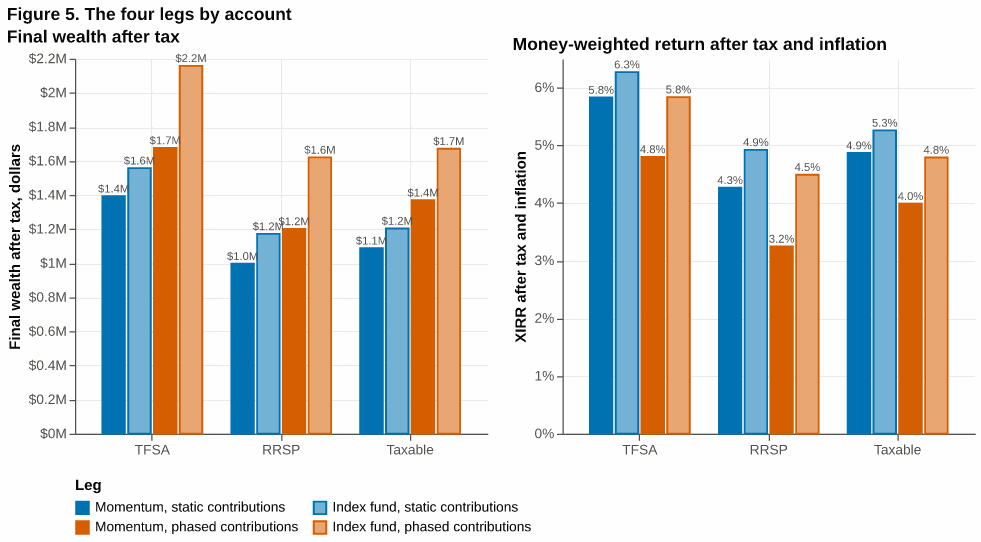

Table 5. The four legs by account (the index fund is the baseline of its schedule in every account)


In [10]:
rows_f, rows_x = [], []
for a in ACCOUNTS:
    for s in SCHEDS:
        for k in ("screen", "index"):
            rows_f.append(dict(group=NAME[a], sched=s, kind=k, value=FINAL[s, a, k]))
            rows_x.append(dict(group=NAME[a], sched=s, kind=k, value=m(s, a, WHO[k], "XIRRAfterTaxReal")))
show(panels([pch.compare_bars(pd.DataFrame(rows_f), SCREEN, value_title="Final wealth after tax, dollars", title="Final wealth after tax", width=330, legend=True),
             pch.compare_bars(pd.DataFrame(rows_x), SCREEN, value_title="XIRR after tax and inflation", fmt="%", tip_fmt=".2%", label_fmt=".1%",
                              title="Money-weighted return after tax and inflation", width=330, legend=False)],
            "Figure 5. The four legs by account", shared=True))

rows = []
for s in SCHEDS:
    for k in ("screen", "index"):
        row = {"Leg": LEG[s, k]}
        for a in ACCOUNTS:
            row[("Final wealth after tax", NAME[a])] = FINAL[s, a, k]
        for a in ACCOUNTS:
            row[("XIRR after tax and inflation", NAME[a])] = m(s, a, WHO[k], "XIRRAfterTaxReal")
        for a in ACCOUNTS:
            row[("Tax paid", NAME[a])] = m(s, a, WHO[k], "TaxPaid")
        row[("Best account", "")] = NAME[max(ACCOUNTS, key=lambda a: FINAL[s, a, k])]
        rows.append(row)
tab5 = pd.DataFrame(rows).set_index("Leg")
tab5.columns = pd.MultiIndex.from_tuples(tab5.columns)
print("Table 5. The four legs by account (the index fund is the baseline of its schedule in every account)")
tab5.style.format({c: fmoney for c in tab5.columns if c[0] in ("Final wealth after tax", "Tax paid")} | {c: "{:.2%}" for c in tab5.columns if c[0].startswith("XIRR")})

In [11]:
assert all(S[s, a][f"{w}_after_tax"].min() > 0 for s in SCHEDS for a in ACCOUNTS for w in ("strategy", "index"))
def spread(c):                              # best minus worst account for a leg
    return FINAL[c[0], best[c], c[1]] - FINAL[c[0], worst[c], c[1]]
tax_more = all(m(s, "taxable", "strategy", "TaxPaid") > m(s, "taxable", "index", "TaxPaid") for s in SCHEDS)
sign_hold = len({DF[s, a] >= 0 for s in SCHEDS for a in ACCOUNTS}) == 1
acct_gap = max(abs(DF[s, a]) for s in SCHEDS for a in ACCOUNTS)
say(f'''
### What the evidence says

Which account holds the money moves the result in dollars. {"; ".join(f"{LEG[c]} ended {usd(spread(c))} higher in the {ACCT[best[c]]} ({usd(FINAL[c[0], best[c], c[1]])}) than in the {ACCT[worst[c]]} ({usd(FINAL[c[0], worst[c], c[1]])})" for c in cols)}. The ranking of the accounts is {"the same for all four legs" if len({tuple(sorted(ACCOUNTS, key=lambda a: -FINAL[c[0], a, c[1]])) for c in cols}) == 1 else "not the same for all four legs"}. The largest gap between the screen and its own baseline in any account is {usd(acct_gap)}, against an account spread of {usd(max(spread(c) for c in cols))} for the leg that moves most, so the account matters {"more" if max(spread(c) for c in cols) > acct_gap else "less"} than the choice between the screen and the index fund. The screen {"was ahead of" if all(DF[s, a] >= 0 for s in SCHEDS for a in ACCOUNTS) else "was behind" if all(DF[s, a] < 0 for s in SCHEDS for a in ACCOUNTS) else "was ahead of the index fund in some accounts and behind it in others, and so was not consistent against"} {"the index fund in every account and under both schedules" if sign_hold else "its baseline"}: the difference in final wealth after tax is {join_and(f"{sd(DF[s, a])} in the {ACCT[a]} under {sched_name(s)}" for s in SCHEDS for a in ACCOUNTS)}. In the taxable account {SCREEN.lower()} paid {usd(m(st, "taxable", "strategy", "TaxPaid"))} of tax under the static schedule against {usd(m(st, "taxable", "index", "TaxPaid"))} for the index fund, {"more" if tax_more else "less"} than its baseline{" although it ended with less wealth, which fits a screen that renews its ten names every year and so realizes gains that the index fund defers" if tax_more and FINAL[st, "taxable", "screen"] < FINAL[st, "taxable", "index"] else ", as expected of a leg that ended with less wealth to tax" if (not tax_more) and FINAL[st, "taxable", "screen"] < FINAL[st, "taxable", "index"] else ""}. The withholding is the whole tax in the TFSA ({usd(m(st, "tfsa", "strategy", "TaxPaid"))} and {usd(m(st, "tfsa", "index", "TaxPaid"))} for the two static legs), and the RRSP's final is after the 30% withdrawal tax, by convention, with no refund on the way in. Because the tax is paid from the portfolio, the after-tax lines stay above zero even through the March 2009 low.
''')


### What the evidence says

Which account holds the money moves the result in dollars. Momentum, static contributions ended \$395,687 higher in the TFSA (\$1,393,105) than in the RRSP (\$997,418); Index fund, static contributions ended \$385,624 higher in the TFSA (\$1,558,015) than in the RRSP (\$1,172,391); Momentum, phased contributions ended \$474,947 higher in the TFSA (\$1,676,580) than in the RRSP (\$1,201,633); Index fund, phased contributions ended \$537,249 higher in the TFSA (\$2,158,435) than in the RRSP (\$1,621,186). The ranking of the accounts is the same for all four legs. The largest gap between the screen and its own baseline in any account is \$481,855, against an account spread of \$537,249 for the leg that moves most, so the account matters more than the choice between the screen and the index fund. The screen was behind the index fund in every account and under both schedules: the difference in final wealth after tax is -\$164,910 in the TFSA under static contributions, -\$174,973 in the RRSP under static contributions, -\$115,870 in the taxable account under static contributions, -\$481,855 in the TFSA under phased contributions, -\$419,553 in the RRSP under phased contributions and -\$302,155 in the taxable account under phased contributions. In the taxable account momentum paid \$270,258 of tax under the static schedule against \$327,447 for the index fund, less than its baseline, as expected of a leg that ended with less wealth to tax. The withholding is the whole tax in the TFSA (\$11,706 and \$45,491 for the two static legs), and the RRSP's final is after the 30% withdrawal tax, by convention, with no refund on the way in. Because the tax is paid from the portfolio, the after-tax lines stay above zero even through the March 2009 low.


## 5. The goal and the timing: when did each leg first hold \$1.5 million, and does it matter when the cash goes in?

A plan usually has a number it is meant to reach. The first question for this section is when each of the four legs first held a nominal \$1,500,000 after tax, and how far from it each finished given the \$3,000 a month taken out from 2018; it compares the legs on the plan's own yardstick, schedule by schedule and instrument by instrument. The plan reports `YearsToGoal` (years from the start until the after-tax wealth first reaches the goal) and `GoalShortfall` (the gap at the end, zero when the goal is met). The second question is whether the cash timing matters: investing each contribution on the next trading day, as the plan does by default (`cash_timing="invest"`), or leaving it in cash until the screen is next renewed (`cash_timing="hold"`), which is what a portfolio that only trades on its rebalance dates would do. The cash earns the library's cash rate, which is zero here. The hold run is made for the static schedule in the TFSA only, and the index fund, which is always invested, is unaffected: it is the baseline in both runs.

Figure 6 draws the TFSA's after-tax wealth of the four legs on a linear scale against the goal, with a marker where each leg first holds it. Figure 7 shows the screen's wealth when invested on arrival and when held in cash, against the index fund (left), and the cash the hold run carries (right). Table 6 gives the goal by account, and Table 7 the cash timing.

**Figure 6.** TFSA wealth after tax of the four legs against the amber \$1.5 million goal, on a linear scale, with a marker where each leg first held the goal. **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** hovering shows the month end, the money put in, the four legs and the screen minus the index fund for each schedule; on a goal marker, the leg, the date it first reached the goal and the years into the plan. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

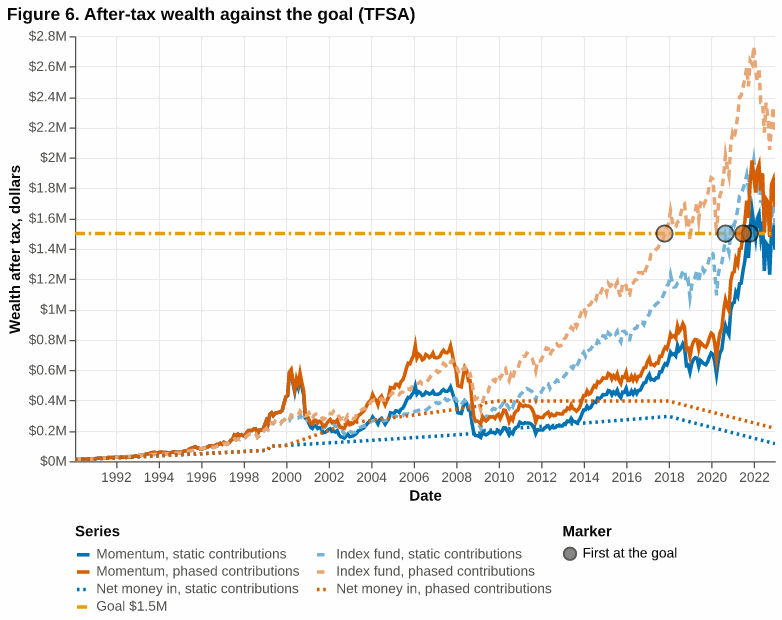

Table 6. The goal, after tax, for the four legs in each account (the index fund is the baseline of its schedule)


In [12]:
show(pch.compare_chart(R, SCREEN, log=False, mark_goal=True, title="Figure 6. After-tax wealth against the goal (TFSA)"))

rows = []
for a in ACCOUNTS:
    for s in SCHEDS:
        for k in ("screen", "index"):
            d = reached[s, a, k]
            rows.append({"Account": NAME[a], "Leg": LEG[s, k], "First at the goal": "never" if d is None else f"{d:%b %Y}",
                         "Years to the goal": m(s, a, WHO[k], "YearsToGoal"), "Final, after tax": FINAL[s, a, k], "Short of the goal at the end": m(s, a, WHO[k], "GoalShortfall")})
tab6 = pd.DataFrame(rows).set_index(["Account", "Leg"])
print("Table 6. The goal, after tax, for the four legs in each account (the index fund is the baseline of its schedule)")
tab6.style.format({"Years to the goal": "{:.1f}", "Final, after tax": fmoney, "Short of the goal at the end": fmoney}, na_rep="never")

**Figure 7.** Left: TFSA wealth after tax under the static schedule on a log scale when each contribution is invested on arrival (solid blue), when it waits in cash until the rebalance (green), and in the index fund (dashed lighter blue), against the net money put in. Right: the uninvested cash the hold run carries. **Tooltip:** left, the date, the money put in, the three wealth values and the cost of waiting (invest minus hold); right, the month end and the cash held. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

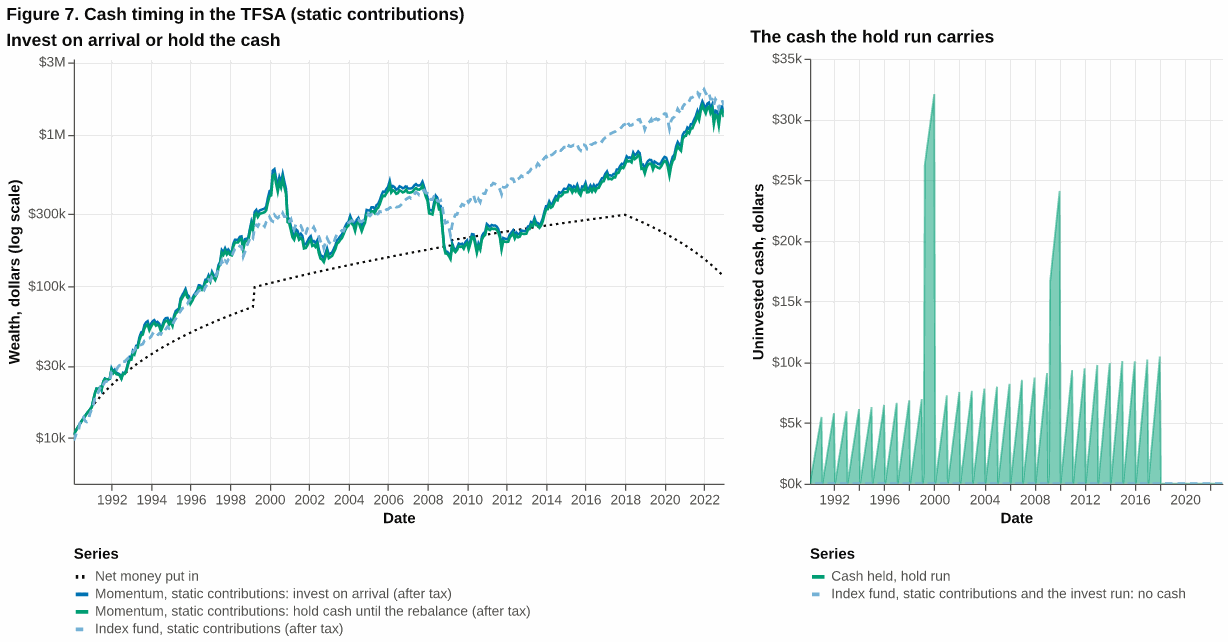

Table 7. Cash timing in the TFSA, static contributions (the index fund is the baseline in both runs)


,"Final, after tax","XIRR, after tax","TWR, after tax",Sharpe
"Momentum, static contributions: invest on arrival","$1,393,105",8.43%,8.85%,0.30
"Momentum, static contributions: hold cash","$1,302,534",8.16%,8.46%,0.29
"Index fund, static contributions","$1,558,015",8.89%,9.23%,0.41


In [13]:
H = hold.series
sc_, ic_ = pch.leg_colors("static")
show(pch.invest_vs_hold_chart(R["static"], hold, strategy_label=LEG["static", "screen"], index_label=LEG["static", "index"],
                              title="Figure 7. Cash timing in the TFSA (static contributions)", y_domain=WEALTH_DOM, colors=(sc_, ic_, "#009E73")))

hm = hold.metrics
f = lambda c, w: m("static", "tfsa", w, c)
tab7 = pd.DataFrame({"Final, after tax": [f("FinalAfterTax", "strategy"), hm.loc["strategy", "FinalAfterTax"], f("FinalAfterTax", "index")],
                     "XIRR, after tax": [f("XIRRAfterTax", "strategy"), hm.loc["strategy", "XIRRAfterTax"], f("XIRRAfterTax", "index")],
                     "TWR, after tax": [f("TWRAfterTax", "strategy"), hm.loc["strategy", "TWRAfterTax"], f("TWRAfterTax", "index")],
                     "Sharpe": [f("Sharpe", "strategy"), hm.loc["strategy", "Sharpe"], f("Sharpe", "index")]},
                    index=[f"{LEG['static', 'screen']}: invest on arrival", f"{LEG['static', 'screen']}: hold cash", LEG["static", "index"]])
print("Table 7. Cash timing in the TFSA, static contributions (the index fund is the baseline in both runs)")
tab7.style.format({"Final, after tax": fmoney, "XIRR, after tax": "{:.2%}", "TWR, after tax": "{:.2%}", "Sharpe": "{:.2f}"})

In [14]:
CASH_AVG, CASH_MAX = float(H["cash"].mean()), float(H["cash"].max())
cost_hold = FINAL["static", "tfsa", "screen"] - hm.loc["strategy", "FinalAfterTax"]
cost_x = f("XIRRAfterTax", "strategy") - hm.loc["strategy", "XIRRAfterTax"]
def gp(s, a, k):                           # the goal in words for one leg in one account
    d, y = reached[s, a, k], m(s, a, WHO[k], "YearsToGoal")
    end = m(s, a, WHO[k], "GoalShortfall")
    first = "never held the goal" if d is None else f"first held the goal in {d:%B %Y} ({y:.1f} years in)"
    return f"{LEG[s, k]} {first} and finished {usd(FINAL[s, a, k] - GOAL)} above it" if end == 0 else f"{LEG[s, k]} {first} and finished {usd(end)} short of it"
met = {a: [LEG[s, k] for s in SCHEDS for k in ("screen", "index") if m(s, a, WHO[k], "GoalShortfall") == 0] for a in ACCOUNTS}
t_first = {c: reached[c[0], "tfsa", c[1]] for c in cols}
earliest = min((c for c in cols if t_first[c] is not None), key=lambda c: t_first[c], default=None)
before_w = [c for c in cols if t_first[c] is not None and t_first[c] < pd.Timestamp(PLAN["withdraw_from"])]
NUMW = ["none", "one", "two", "three", "all"]
yg = lambda s, k: m(s, "tfsa", WHO[k], "YearsToGoal")
say(f'''
### What the evidence says

In the TFSA, after tax, the goal of {usd(GOAL)} was reached as follows. {"; ".join(gp(c[0], "tfsa", c[1]) for c in cols)}. {"The first leg to hold the goal was " + LEG[earliest] + " in " + format(t_first[earliest], "%B %Y") + "." if earliest is not None else "No leg held the goal."} The screen reached the goal {"before" if yg(st, "screen") < yg(st, "index") else "after"} its baseline under the static schedule ({yrs(yg(st, "screen"))} years against {yrs(yg(st, "index"))}) and {"before" if yg(ph, "screen") < yg(ph, "index") else "after"} its baseline under the phased schedule ({yrs(yg(ph, "screen"))} against {yrs(yg(ph, "index"))}). At the end of 2022 the goal was met after tax by {NUMW[len(met["tfsa"])]} of the four legs in the TFSA, {NUMW[len(met["rrsp"])]} in the RRSP (where 30% of the balance is owed on withdrawal) and {NUMW[len(met["taxable"])]} in the taxable account (where each year's tax comes out of the portfolio and stops compounding){": " + "; ".join(f"in the {ACCT[a]}, {', '.join(met[a]) if met[a] else 'none'}" for a in ACCOUNTS) if any(met.values()) else ""}. {NUMW[len(before_w)].capitalize()} of the four legs had held the goal in the TFSA before the withdrawals of {usd(PLAN["withdrawals"])} a month began in January 2018. Section 6 asks how often a different order of the same returns would have missed it.

The cash timing {"cost" if cost_hold > 0 else "helped by"} {usd(abs(cost_hold))} here: investing each contribution on arrival ended at {usd(FINAL["static", "tfsa", "screen"])} after tax in the TFSA and holding it in cash until the next rebalance at {usd(hm.loc["strategy", "FinalAfterTax"])}, a difference of {pc(abs(cost_hold) / FINAL["static", "tfsa", "screen"])} of the final wealth, or {pts(abs(cost_x))} points of money-weighted return a year. The hold run carried {usd(CASH_AVG)} of cash on average and {usd(CASH_MAX)} at most. {"Waiting cost money because stocks rose in this history; in a decade that fell, holding cash would have helped." if cost_hold > 0 else "Waiting helped because the screen's holdings fell on average after each contribution in this history."} The default of investing on arrival is the better description of a monthly saver, and the hold run is the right model for a portfolio that only trades on its rebalance dates. The screen finished {usd(abs(hm.loc["difference", "FinalAfterTax"]))} {ahead(hm.loc["difference", "FinalAfterTax"])} the index fund with the cash held, so the conclusion about the screen against its baseline {"does not depend" if (hm.loc["difference", "FinalAfterTax"] >= 0) == (DF[st, "tfsa"] >= 0) else "depends"} on the choice.
''')
assert H["cash"].max() > 0 and S["static", "tfsa"]["cash"].max() == 0


### What the evidence says

In the TFSA, after tax, the goal of \$1,500,000 was reached as follows. Momentum, static contributions first held the goal in October 2021 (31.8 years in) and finished \$106,895 short of it; Index fund, static contributions first held the goal in September 2020 (30.7 years in) and finished \$58,015 above it; Momentum, phased contributions first held the goal in June 2021 (31.5 years in) and finished \$176,580 above it; Index fund, phased contributions first held the goal in October 2017 (27.8 years in) and finished \$658,435 above it. The first leg to hold the goal was Index fund, phased contributions in October 2017. The screen reached the goal after its baseline under the static schedule (31.8 years against 30.7) and after its baseline under the phased schedule (31.5 against 27.8). At the end of 2022 the goal was met after tax by three of the four legs in the TFSA, one in the RRSP (where 30% of the balance is owed on withdrawal) and one in the taxable account (where each year's tax comes out of the portfolio and stops compounding): in the TFSA, Index fund, static contributions, Momentum, phased contributions, Index fund, phased contributions; in the RRSP, Index fund, phased contributions; in the taxable account, Index fund, phased contributions. One of the four legs had held the goal in the TFSA before the withdrawals of \$3,000 a month began in January 2018. Section 6 asks how often a different order of the same returns would have missed it.

The cash timing cost \$90,571 here: investing each contribution on arrival ended at \$1,393,105 after tax in the TFSA and holding it in cash until the next rebalance at \$1,302,534, a difference of 6.50% of the final wealth, or 0.27 points of money-weighted return a year. The hold run carried \$4,449 of cash on average and \$32,093 at most. Waiting cost money because stocks rose in this history; in a decade that fell, holding cash would have helped. The default of investing on arrival is the better description of a monthly saver, and the hold run is the right model for a portfolio that only trades on its rebalance dates. The screen finished \$255,481 behind the index fund with the cash held, so the conclusion about the screen against its baseline does not depend on the choice.


## 6. Risk: Monte Carlo on the four legs in the TFSA

The straight calculation is one path. The question for this section is how the four legs would have fared on other orders of the same months: how often the screen would have finished ahead of the index fund of its own schedule after tax, how often each leg would have missed the \$1.5 million goal, and what the worst twelve months did when they came early or late. It makes the same comparisons as Sections 2, 3 and 5, the screen against the index fund of each schedule and one schedule against the other, on resampled instead of historical returns, so it follows from the three answers they gave, and it is run in the TFSA for both schedules (a taxable-account run is left out to keep the notebook to a few minutes). The study resamples the plan's own monthly history (the screen, the index fund, the risk-free rate and inflation together, in 12-month blocks, so a bad year for one is a bad year for the other) into 500 paths of the same 33 years, replays each schedule's dated flows on every path, and pays on each path, every year, the share of the portfolio that the straight run paid in tax that year (in the TFSA, the withholding). That is an approximation, not a re-simulation; Section 7 says what it leaves out.

Figure 8 is the fan of after-tax wealth, the static schedule on the left and the phased schedule on the right: the median of the screen and of the index fund with their 25-75% and 5-95% bands, the net money put in, and the goal. Figure 9 shows the terminal wealth of the two legs of each schedule and, path by path, the screen minus the index fund. Figure 10 groups the paths of the static schedule by where their worst twelve months fell, and plays the same returns in the opposite order. Table 8 gives the percentiles.

**Figure 8.** The fan of 500 resampled paths in the TFSA, static schedule (left) and phased schedule (right), on a log scale: the median of the screen (solid) and of the index fund (dashed, lighter), the dark bands holding the middle half of paths (25th to 75th percentile) and the light bands holding 90% (5th to 95th), the net money put in (dotted) and the goal (amber). **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** hovering shows the month, the money put in, and for each leg the median, the 25th, 75th, 5th and 95th percentiles. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

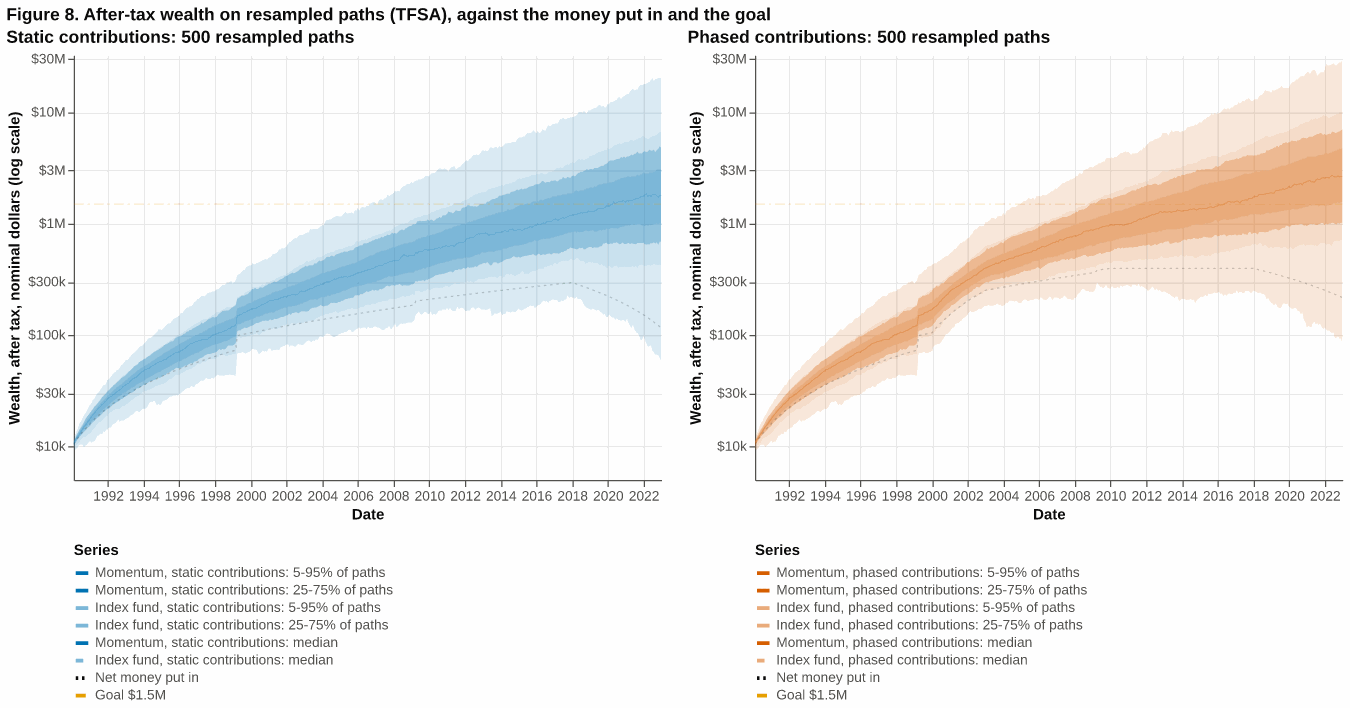

In [15]:
FAN_TOP = 1.1 * max(float(mcs[s].fan[["strategy_p95", "index_p95"]].max().max()) for s in SCHEDS)
show(panels([pch.fan_chart(mcs[s], strategy_label=LEG[s, "screen"], index_label=LEG[s, "index"], y_domain=(5_000, FAN_TOP), width=470,
                           colors=pch.leg_colors(s), title=f"{sched_name(s).capitalize()}: {N_PATHS} resampled paths") for s in SCHEDS],
            "Figure 8. After-tax wealth on resampled paths (TFSA), against the money put in and the goal"))

**Figure 9.** Top: terminal after-tax wealth on every path in the TFSA, the screen against the index fund for each schedule, with the medians, the goal and the money put in as vertical lines (the last bar holds every path above the 99.5th percentile). Bottom: the screen minus the index fund on the same path, the share ahead in the schedule's colour and the share behind in grey. **Colour is the contribution schedule (blue for static, vermillion for phased); a solid line is the screen, a dashed lighter line of the same colour is the index fund that received the same dollars on the same days; the dotted line is the net money put in.** **Tooltip:** on a bar, the bin from and to in dollars, the number of paths and their share of all paths; on a vertical line, its meaning and dollar value. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

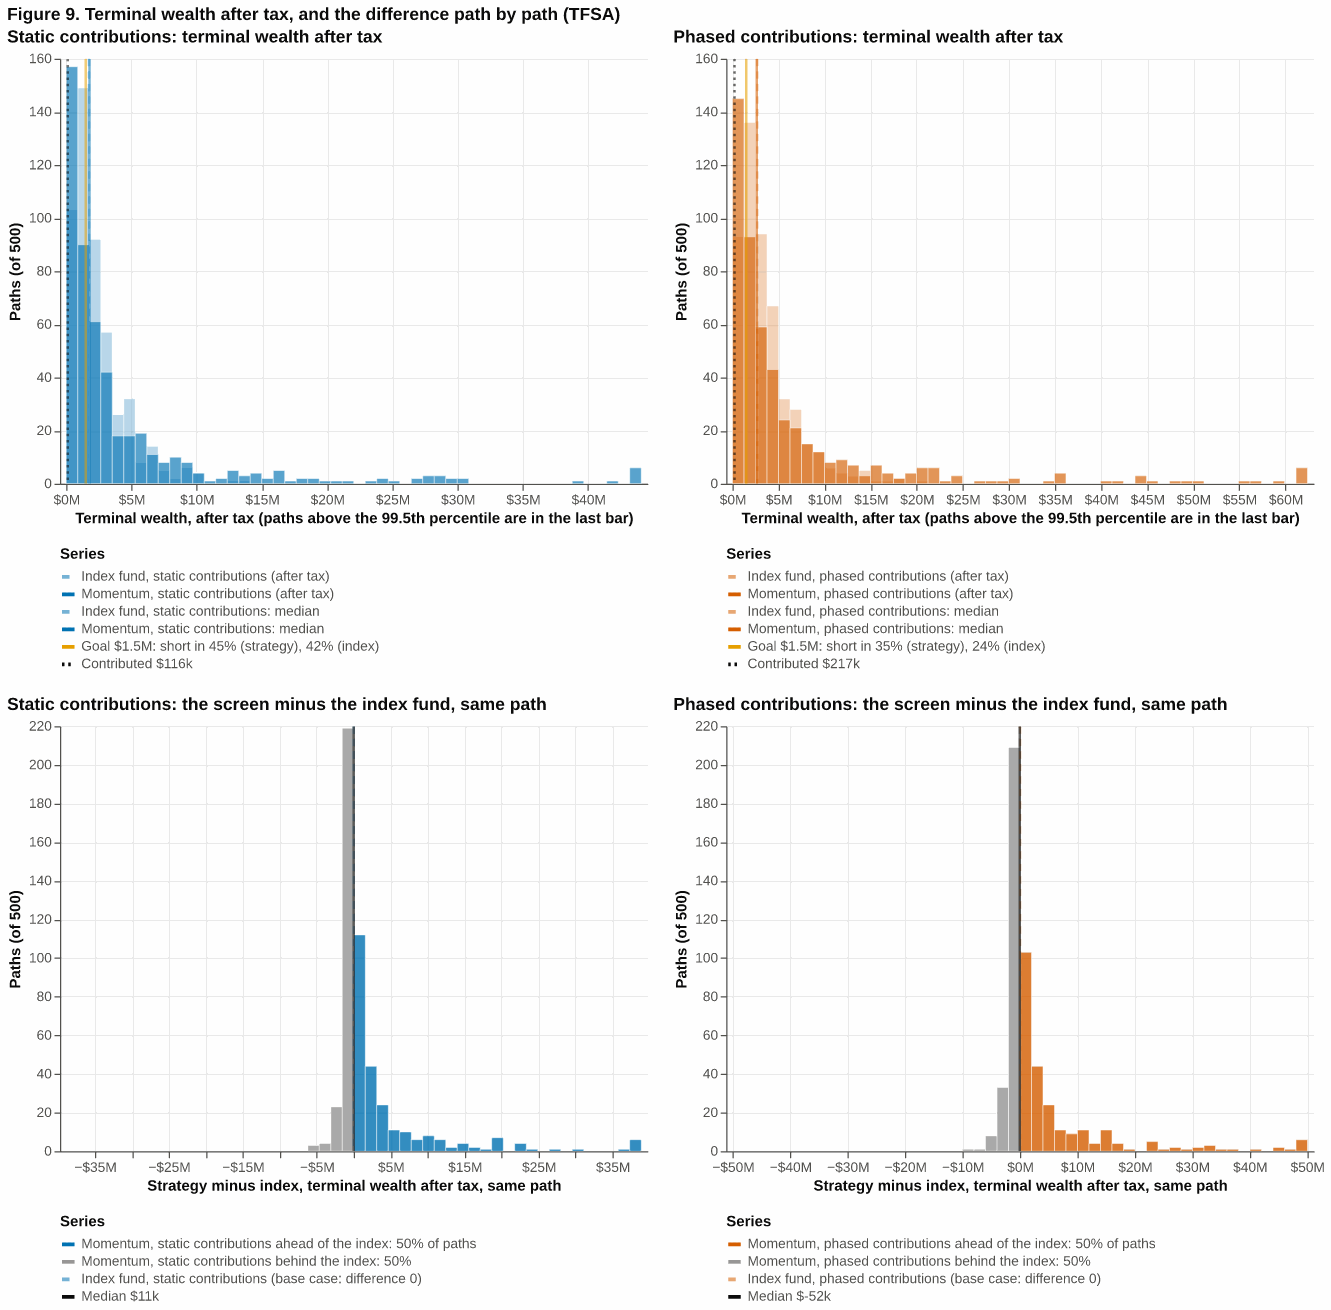

In [16]:
show(panels([pch.terminal_hist(mcs[s], strategy_label=LEG[s, "screen"], index_label=LEG[s, "index"], width=470, colors=pch.leg_colors(s),
                               title=f"{sched_name(s).capitalize()}: terminal wealth after tax") for s in SCHEDS]
            + [pch.paired_hist(mcs[s], strategy_label=LEG[s, "screen"], index_label=LEG[s, "index"], width=470, colors=pch.leg_colors(s),
                               title=f"{sched_name(s).capitalize()}: the screen minus the index fund, same path") for s in SCHEDS],
            "Figure 9. Terminal wealth after tax, and the difference path by path (TFSA)", columns=2))

**Figure 10.** Static schedule, TFSA: median terminal wealth after tax by where the path's worst 12 months fall (first, middle or last third of the plan), and the historical path in order against the same returns reversed, with the net money put in. **Colour is the contribution schedule (blue for static, vermillion for phased); a dark bar is the screen, a lighter bar of the same colour is the index fund that received the same dollars on the same days.** **Tooltip:** on a bar, the leg, the group, the exact dollars, the number of paths in the group and the share of the screen's paths below the goal; on the reversal bars, the leg, the order and the dollars. Hover over any mark for its exact values; drag to pan and scroll to zoom (JupyterLab or VS Code; elsewhere the picture is static).

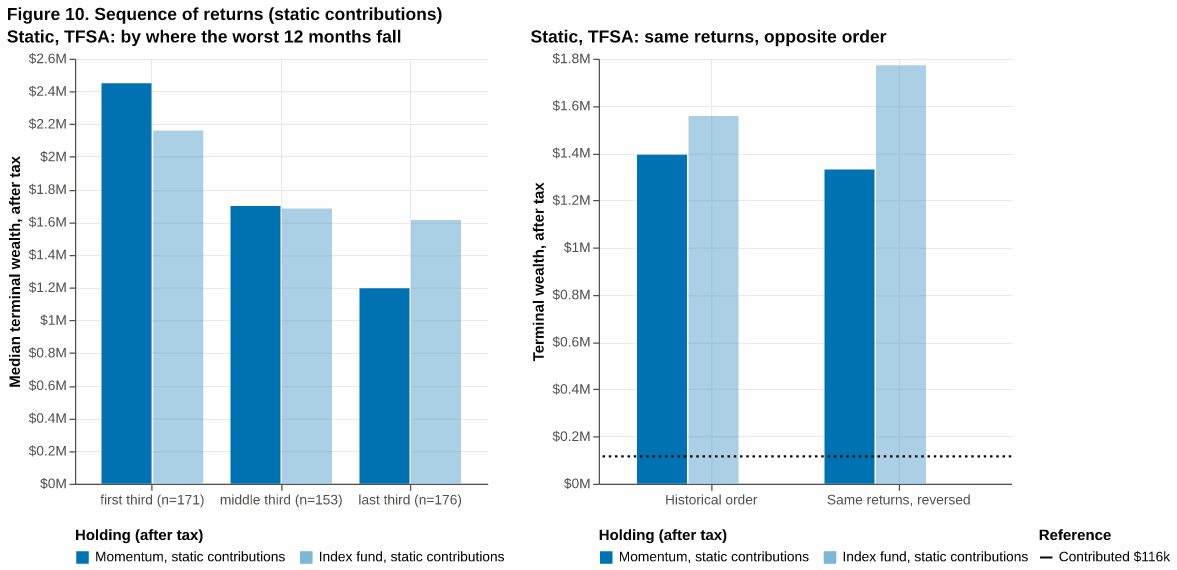

Table 8. Terminal wealth after tax on 500 resampled paths in the TFSA (the index fund is the baseline of its schedule)


,5th percentile,25th percentile,50th percentile,75th percentile,95th percentile,Screen ahead of the index fund,Short of the goal
Leg,,,,,,,
"Momentum, static contributions","$58,131","$684,465","$1,783,551","$4,768,735","$20,409,469",50%,45%
"Index fund, static contributions","$417,858","$1,010,870","$1,747,389","$3,105,862","$6,632,108",,42%
"Momentum, phased contributions","$80,087","$1,019,079","$2,627,710","$6,974,039","$29,656,046",50%,35%
"Index fund, phased contributions","$716,905","$1,569,253","$2,677,299","$4,707,552","$9,897,091",,24%


In [17]:
show(panels([pch.sequence_chart(mcs["static"], strategy_label=LEG["static", "screen"], index_label=LEG["static", "index"], width=330, colors=pch.leg_colors("static"),
                                title="Static, TFSA: by where the worst 12 months fall"),
             pch.reversal_chart(mcs["static"], strategy_label=LEG["static", "screen"], index_label=LEG["static", "index"], width=330, colors=pch.leg_colors("static"),
                                title="Static, TFSA: same returns, opposite order")],
            "Figure 10. Sequence of returns (static contributions)"))

rows = []
for s in SCHEDS:
    q = mcs[s].quantiles
    for k, who in (("screen", "strategy"), ("index", "index")):
        rows.append({"Leg": LEG[s, k], **{f"{p}th percentile": q.loc[p, f"{who}_after_tax"] for p in (5, 25, 50, 75, 95)},
                     "Screen ahead of the index fund": mcs[s].p_beat_index if k == "screen" else np.nan,
                     "Short of the goal": mcs[s].p_shortfall if k == "screen" else mcs[s].p_shortfall_index})
tab8 = pd.DataFrame(rows).set_index("Leg")
print("Table 8. Terminal wealth after tax on", N_PATHS, "resampled paths in the TFSA (the index fund is the baseline of its schedule)")
tab8.style.format({c: fmoney for c in tab8.columns[:5]} | {"Screen ahead of the index fund": "{:.0%}", "Short of the goal": "{:.0%}"}, na_rep="")

In [18]:
sq = mcs["static"].sequence
rv = mcs["static"].reversal
q = lambda s, p, w: mcs[s].quantiles.loc[p, f"{w}_after_tax"]
low_third = min(("first", "middle", "last"), key=lambda i: sq.loc[i, "strategy_median"])
high_third = max(("first", "middle", "last"), key=lambda i: sq.loc[i, "strategy_median"])
rev_up = rv.loc["reversed", "strategy_after_tax"] > rv.loc["forward", "strategy_after_tax"]
pbs = [mcs[s].p_beat_index for s in SCHEDS]
trailed = DF["static", "tfsa"] < 0
PB_TEXT = (f"That is close to a coin toss under both schedules, so the order of the returns, more than the screen, decides which leg finishes ahead; the straight run, in which the screen finished {'behind' if trailed else 'ahead'}, is one draw." if all(0.45 <= p <= 0.55 for p in pbs) else
           f"That is fewer than half of the paths under both schedules, so finishing behind the index fund is the more common outcome." if max(pbs) < 0.45 else
           f"That is more than half of the paths under both schedules, so finishing ahead of the index fund is the more common outcome, but it is far from certain." if min(pbs) > 0.55 else
           f"That is mixed across the two schedules, so the straight run's result does not settle which leg is better.")
say(f'''
### What the evidence says

In the TFSA {SCREEN.lower()} finished ahead of the index fund after tax on {pc(pbs[0])} of {N_PATHS} resampled paths under static contributions and on {pc(pbs[1])} under phased contributions. {PB_TEXT} The straight run itself, replayed through the Monte Carlo in its own order, reproduces the straight calculation to the dollar ({usd(REPLAY["static", "tfsa", "screen"])} for {LEG["static", "screen"]} and {usd(REPLAY["phased", "tfsa", "screen"])} for {LEG["phased", "screen"]}), at the {ordn(100 * HIST_PCT["static"])} and {ordn(100 * HIST_PCT["phased"])} percentile of the resampled terminal wealth. The median after-tax final wealth was {usd(q(st, 50, "strategy"))} for {LEG[st, "screen"]} against {usd(q(st, 50, "index"))} for {LEG[st, "index"]}, and {usd(q(ph, 50, "strategy"))} against {usd(q(ph, 50, "index"))} under the phased schedule. The spread is wide: the static screen's 5th percentile was {usd(q(st, 5, "strategy"))} and its 95th {usd(q(st, 95, "strategy"))}, against {usd(q(st, 5, "index"))} and {usd(q(st, 95, "index"))} for its baseline, so the screen {"has a wider range than" if (q(st, 95, "strategy") - q(st, 5, "strategy")) > (q(st, 95, "index") - q(st, 5, "index")) else "has a narrower range than"} the index fund. The share of paths that finished below {usd(GOAL)} was {pc(mcs[st].p_shortfall)} for {LEG[st, "screen"]} against {pc(mcs[st].p_shortfall_index)} for {LEG[st, "index"]}, and {pc(mcs[ph].p_shortfall)} for {LEG[ph, "screen"]} against {pc(mcs[ph].p_shortfall_index)} for {LEG[ph, "index"]}.

The order of the returns matters through the withdrawals. For the static schedule, when the worst twelve months fell in the first third of the plan the screen's median TFSA outcome was {usd(sq.loc["first", "strategy_median"])}, in the middle third {usd(sq.loc["middle", "strategy_median"])} and in the last third {usd(sq.loc["last", "strategy_median"])}, and the share of paths below the goal was {pc(sq.loc["first", "p_shortfall"])}, {pc(sq.loc["middle", "p_shortfall"])} and {pc(sq.loc["last", "p_shortfall"])}; the lowest median came when the worst year fell in the {low_third} third and the highest when it fell in the {high_third} third. Playing the same historical returns in the opposite order, with the same flows, gives {usd(rv.loc["reversed", "strategy_after_tax"])} for the screen against {usd(rv.loc["forward", "strategy_after_tax"])} in the order that happened ({usd(rv.loc["reversed", "index_after_tax"])} against {usd(rv.loc["forward", "index_after_tax"])} for the index fund): the plan finishes {"higher" if rev_up else "lower"} when the same returns arrive in reverse, so the order that happened was {"not a favourable one" if rev_up else "a favourable one"} for it.
''')


### What the evidence says

In the TFSA momentum finished ahead of the index fund after tax on 50.20% of 500 resampled paths under static contributions and on 49.60% under phased contributions. That is close to a coin toss under both schedules, so the order of the returns, more than the screen, decides which leg finishes ahead; the straight run, in which the screen finished behind, is one draw. The straight run itself, replayed through the Monte Carlo in its own order, reproduces the straight calculation to the dollar (\$1,393,105 for Momentum, static contributions and \$1,676,580 for Momentum, phased contributions), at the 43rd and 37th percentile of the resampled terminal wealth. The median after-tax final wealth was \$1,783,551 for Momentum, static contributions against \$1,747,389 for Index fund, static contributions, and \$2,627,710 against \$2,677,299 under the phased schedule. The spread is wide: the static screen's 5th percentile was \$58,131 and its 95th \$20,409,469, against \$417,858 and \$6,632,108 for its baseline, so the screen has a wider range than the index fund. The share of paths that finished below \$1,500,000 was 45.20% for Momentum, static contributions against 42.00% for Index fund, static contributions, and 35.00% for Momentum, phased contributions against 24.20% for Index fund, phased contributions.

The order of the returns matters through the withdrawals. For the static schedule, when the worst twelve months fell in the first third of the plan the screen's median TFSA outcome was \$2,449,353, in the middle third \$1,699,519 and in the last third \$1,196,574, and the share of paths below the goal was 34.50%, 47.06% and 53.98%; the lowest median came when the worst year fell in the last third and the highest when it fell in the first third. Playing the same historical returns in the opposite order, with the same flows, gives \$1,331,289 for the screen against \$1,393,105 in the order that happened (\$1,772,496 against \$1,558,015 for the index fund): the plan finishes lower when the same returns arrive in reverse, so the order that happened was a favourable one for it.


## 7. How to read these numbers

The question this section answers is what the figures stand on, and what they leave out. The points below are the ones that move a result.

* **The history is real, and for local use only.** The panel is the point-in-time S&P 500, 1990 to 2022, with the companies that were in the index on each date and their real prices and dividends. A name whose prices end (delisted, merged) takes the library's delisting haircut of 30%, which is harsh for acquisitions paid at a premium. The data is an unlicensed mixed-source panel: do not commit or share it or results that embed it.
* **Inflation is US CPI, and the risk-free rate is the US 10-year yield.** Both are expediencies, recorded in `docs/DECISIONS.md`: the Canadian series (StatCan CPI, the Bank of Canada 10-year benchmark) were not reachable from the build environment. A Canadian investor's real return is a different number, and the Sharpe ratio and alpha would shift with a Canadian rate. The plan's card states which series was used, and a Canadian series replaces these automatically once it is loaded.
* **Tax is the 2025 Canadian tables for every year.** The warnings that print under the card ("no tax table, used 2025") say so for each year of the run. Alberta, other income \$90,000 a year, US dividends withheld at 15%. The RRSP is taxed at one flat 30% on the whole balance, with no deduction refund on the way in. Contribution room is not checked: a TFSA that holds \$3 million is not one the room would have allowed. No AMT. In the straight calculation and in the Monte Carlo the tax is paid from the portfolio at each year's last trading day (the option `tax_from_outside=True` restores the older basis, in which it is paid from money outside the account and the after-tax line can fall below the portfolio's worth).
* **The Monte Carlo approximates tax, on the same basis as the straight run.** Each path pays, every year, the share of the portfolio the straight run paid in tax that year, with no lots, no path-dependent loss harvesting and no extra gain tax on mid-plan withdrawals, so on a path that differs from history the tax is only roughly right; replayed on the recorded months in their own order it equals the straight run exactly (checked to the dollar for the six runs of this notebook, in Summary and in Section 6). It resamples months in 12-month blocks, so it keeps a year's worth of serial dependence and nothing longer. It describes how this history could have been ordered, not what the next 33 years will do. The study takes 500 paths here to keep the run short; 1,000 or more tighten the percentages by a point or two.
* **One screen, chosen for its definition and not for its result, and one start.** `momentum_12m` is the standard momentum rule (the best twelve-month return, renewed yearly), not the best-looking momentum variant: the six-month variant (`momentum_6m`) changes sign with the rebalance timing (Appendix A), and picking the flattering one would be a search over rules. The value screens cannot run on this panel, which carries prices and dividends but no market capitalisation or fundamentals. The plan also starts on one day; starting in another year, or holding a different rule, changes the numbers a great deal, and a result like this one is a reason to test more, not to believe it.

In [19]:
same_sign = all((DF[s, a] >= 0) == (DF["static", "tfsa"] >= 0) for s in SCHEDS for a in ACCOUNTS)
say(f'''
### What the evidence says

The conclusions that hold up are the comparative ones, because each leg shares the flows, the data and the tax with its baseline: {SCREEN.lower()} {"finished ahead of" if DF[st, "tfsa"] >= 0 else "finished behind"} the index fund in the TFSA under the static schedule, and the sign {"is the same" if same_sign else "is not the same"} across both schedules and all three accounts. Measured by the money-weighted and the time-weighted return the gap was {spts(m(st, "tfsa", "difference", "XIRR"))} and {spts(m(st, "tfsa", "difference", "TWR"))} points a year before tax, with {"higher" if m(st, "tfsa", "strategy", "Vol") > m(st, "tfsa", "index", "Vol") else "lower"} volatility and {"a deeper" if m(st, "tfsa", "strategy", "MaxDD") < m(st, "tfsa", "index", "MaxDD") else "a shallower"} fall than the baseline, and the account chosen moved the final dollars by up to {usd(max(abs(FINAL[c[0], best[c], c[1]] - FINAL[c[0], worst[c], c[1]]) for c in cols))} for one leg. The levels do not hold up as forecasts: they rest on one ordering of one market, on 2025 tax tables applied to 1990, and on US stand-ins for the Canadian inflation and rate series.
''')


### What the evidence says

The conclusions that hold up are the comparative ones, because each leg shares the flows, the data and the tax with its baseline: momentum finished behind the index fund in the TFSA under the static schedule, and the sign is the same across both schedules and all three accounts. Measured by the money-weighted and the time-weighted return the gap was -0.66 and -0.60 points a year before tax, with higher volatility and a deeper fall than the baseline, and the account chosen moved the final dollars by up to \$537,249 for one leg. The levels do not hold up as forecasts: they rest on one ordering of one market, on 2025 tax tables applied to 1990, and on US stand-ins for the Canadian inflation and rate series.


## Appendix A. Does the choice of screen matter?

The question for this appendix is whether the case study would have told the same story with another screen, and why `momentum_12m` was used. It compares the library's screens that can run on the real panel with the index, on one lump sum and without tax, and so it is a different measurement from the plan of Sections 1 to 6; it is here to show how much the answer depends on the screen and on when it is renewed. The value screens (`screaming_value` and `value_momentum`, and the net-net, Piotroski and Magic Formula rules behind them) cannot run: they need market capitalisation and fundamentals, and the real panel has only prices and dividends. Table 9 gives the pre-tax compound annual growth rate from 1990 to 2022 of each screen that does run, against the S&P 500 total return, renewed every 12 months and every 6 months.

In [20]:
APP = ["dogs", "momentum_12m", "momentum_6m", "stable_high_yield", "stable_dividend"]
BT = {rb: lab.backtest(APP, rebalance_months=rb, start=START) for rb in (12, 6)}
BENCH = [i for i in BT[12].table.index if i not in APP][0]                      # the index row, SP500_TR
cagr = {rb: BT[rb].table["CAGR"] for rb in BT}
rows = [{"Screen": s, "12-month rebalance": cagr[12][s], "6-month rebalance": cagr[6][s],
         "Versus the index, 12 months": cagr[12][s] - cagr[12][BENCH], "Versus the index, 6 months": cagr[6][s] - cagr[6][BENCH],
         "Ahead of the index at": ("both" if cagr[12][s] > cagr[12][BENCH] and cagr[6][s] > cagr[6][BENCH] else "neither" if cagr[12][s] <= cagr[12][BENCH] and cagr[6][s] <= cagr[6][BENCH]
                                  else "12 months only" if cagr[12][s] > cagr[12][BENCH] else "6 months only")} for s in APP]
rows.append({"Screen": f"{BENCH} (the index)", "12-month rebalance": cagr[12][BENCH], "6-month rebalance": cagr[6][BENCH],
             "Versus the index, 12 months": 0.0, "Versus the index, 6 months": 0.0, "Ahead of the index at": "-"})
tab9 = pd.DataFrame(rows).set_index("Screen")
print("Table 9. Pre-tax CAGR, 1990-2022, by screen and rebalance frequency (a lump sum, no contributions, no tax; the index is SP500_TR)")
tab9.style.format({c: "{:.2%}" for c in tab9.columns[:2]} | {c: "{:+.2%}" for c in tab9.columns[2:4]})

Table 9. Pre-tax CAGR, 1990-2022, by screen and rebalance frequency (a lump sum, no contributions, no tax; the index is SP500_TR)


,12-month rebalance,6-month rebalance,"Versus the index, 12 months","Versus the index, 6 months",Ahead of the index at
Screen,,,,,
dogs,13.24%,12.76%,+3.64%,+3.16%,both
momentum_12m,8.94%,8.99%,-0.65%,-0.61%,neither
momentum_6m,10.74%,7.77%,+1.14%,-1.82%,12 months only
stable_high_yield,8.88%,9.53%,-0.72%,-0.06%,neither
stable_dividend,8.45%,8.64%,-1.14%,-0.96%,neither
SP500_TR (the index),9.59%,9.59%,+0.00%,+0.00%,-


In [21]:
both = [s for s in APP if tab9.loc[s, "Ahead of the index at"] == "both"]
flip = [s for s in APP if tab9.loc[s, "Ahead of the index at"] in ("12 months only", "6 months only")]
neither = [s for s in APP if tab9.loc[s, "Ahead of the index at"] == "neither"]
VALUE_ABSENT = [s for s in ("screaming_value", "value_momentum") if s not in lab.screens]
c12, c6 = cagr[12], cagr[6]
gap = lambda s: f"{100 * (c12[s] - c12[BENCH]):+.1f} points a year at 12 months, {100 * (c6[s] - c6[BENCH]):+.1f} at 6"
t1 = ("The only screen ahead of the index at both rebalance frequencies is " + both[0] + ".") if len(both) == 1 else ("The screens ahead of the index at both rebalance frequencies are " + join_and(both) + ".") if both else "No screen is ahead of the index at both rebalance frequencies."
t2 = ("The screen whose sign flips with the rebalance timing is " if len(flip) == 1 else "The screens whose sign flips with the rebalance timing are ") + join_and(f"{s} ({gap(s)})" for s in flip) + "." if flip else "No screen flips sign with the timing."
t3 = (("The one behind at both is " if len(neither) == 1 else "The ones behind at both are ") + join_and(neither) + ".") if neither else "No screen is behind at both."
where = "ahead of the index at both frequencies" if STRAT in both else "behind the index at both frequencies" if STRAT in neither else "ahead at only one frequency, so its sign depends on the timing"
t4 = f"The case-study screen, {STRAT}, is {where} ({gap(STRAT)})." if STRAT in APP else ""
t5 = ("The momentum rule used here, momentum_12m, is the standard definition; momentum_6m is not used because " +
      ("its sign flips with the rebalance timing, and picking a variant by its result would be a search over rules." if "momentum_6m" in flip else "it adds nothing to the comparison.")) if STRAT == "momentum_12m" else ""
t6 = ("Dogs is the only screen ahead of the index at both frequencies, so to run the case study on a screen that beats the index here, set STRAT to dogs in the first code cell; it is the result of one lump sum on one history, and the screen was not chosen in advance."
      if both == ["dogs"] else "Set STRAT in the first code cell to run the case study on any screen of Table 9.")
t7 = ("The value screens (" + ", ".join(VALUE_ABSENT) + ") are not in this lab, so no value portfolio could be run.") if VALUE_ABSENT else ""
say(f'''
### What the evidence says

{t1} {t2} {t3} {t4} {t5} {t6} {t7}
''')


### What the evidence says

The only screen ahead of the index at both rebalance frequencies is dogs. The screen whose sign flips with the rebalance timing is momentum_6m (+1.1 points a year at 12 months, -1.8 at 6). The ones behind at both are momentum_12m, stable_high_yield and stable_dividend. The case-study screen, momentum_12m, is behind the index at both frequencies (-0.7 points a year at 12 months, -0.6 at 6). The momentum rule used here, momentum_12m, is the standard definition; momentum_6m is not used because its sign flips with the rebalance timing, and picking a variant by its result would be a search over rules. Dogs is the only screen ahead of the index at both frequencies, so to run the case study on a screen that beats the index here, set STRAT to dogs in the first code cell; it is the result of one lump sum on one history, and the screen was not chosen in advance. The value screens (screaming_value, value_momentum) are not in this lab, so no value portfolio could be run.
